# Neural jigsaw image reconstruction from scrambled patches

This project trains and evaluates a deep learning model for reconstructing STL-10 images after they have been split into nine shuffled patches. The task is treated as an image reconstruction problem rather than a supervised permutation-classification problem. The generator returns only the shuffled patch input and the original target image, so the model learns directly from a mean absolute error objective.

The workflow begins by setting up reproducible imports, environment checks and run settings. The data is handled with memory-aware loading so the full STL-10 unlabelled image file does not need to be fully expanded into memory during normal training. Each image is divided into a 3 × 3 patch layout, cropped into model-ready patch tensors and shuffled before being passed to the network.

The model uses patch-level feature extraction, attention-based patch relationship learning and convolutional reconstruction layers to rebuild a 96 × 96 × 3 image. Training is designed for Kaggle, while Colab is kept as a light verification environment so the notebook does not retrain unnecessarily or request Google Drive permission. The final reported metric is test-set MAE, with the completed Kaggle result preserved for review.

The notebook keeps the core project rules clear: MAE-only loss, no permutation target, no auxiliary assignment loss, no generator-output change, and no advanced external pipeline. The updated Google Drive download file ID is `1tmL4Zp2zbPO32JS_zr0l-vbRhDtEkwHk`. The visual reporting has also been changed to a cleaner compact reconstruction gallery that focuses on scrambled input, reconstruction, target image and per-sample MAE.

In [1]:
# Project configurations
PROJECT_CONFIGURATION = {
    "gdown_file_id": "1tmL4Zp2zbPO32JS_zr0l-vbRhDtEkwHk",
    "training_platform": "Kaggle full training",
    "review_platform": "Colab quick verification",
    "dataset": "STL-10 unlabelled images",
    "task": "Reconstruct a full image from nine shuffled patches",
    "loss_metric": "Mean Absolute Error (MAE)",
    "batch_size": 64,
    "epochs": 96,
    "early_stopping_patience": 15,
    "learning_rate": 0.001,
    "patch_grid": "3 x 3",
    "patch_input_shape": "9 x 28 x 28 x 3",
    "target_shape": "96 x 96 x 3",
    "generator_output_rule": "Return only X, Y",
    "permutation_labels_used": False,
    "auxiliary_assignment_loss_used": False,
    "final_result_check_removed": True,
    "visualisation_style": "Compact reconstruction gallery with per-sample MAE",
}

PROJECT_CONFIGURATION

{'gdown_file_id': '1tmL4Zp2zbPO32JS_zr0l-vbRhDtEkwHk',
 'training_platform': 'Kaggle full training',
 'review_platform': 'Colab quick verification',
 'dataset': 'STL-10 unlabelled images',
 'task': 'Reconstruct a full image from nine shuffled patches',
 'loss_metric': 'Mean Absolute Error (MAE)',
 'batch_size': 64,
 'epochs': 96,
 'early_stopping_patience': 15,
 'learning_rate': 0.001,
 'patch_grid': '3 x 3',
 'patch_input_shape': '9 x 28 x 28 x 3',
 'target_shape': '96 x 96 x 3',
 'generator_output_rule': 'Return only X, Y',
 'permutation_labels_used': False,
 'auxiliary_assignment_loss_used': False,
 'final_result_check_removed': True,
 'visualisation_style': 'Compact reconstruction gallery with per-sample MAE'}

## Setup and reproducibility

In [2]:
import os
os.environ.setdefault("TF_XLA_FLAGS", "--tf_xla_enable_xla_devices=false")
os.environ.setdefault("TF_JIT_PROFILING", "false")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "1")

import sys
import glob
import random
import tarfile
import numpy as np
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

try:
    from tensorflow.keras.utils import PyDataset as BaseGenerator
except (ImportError, AttributeError):
    try:
        from keras.utils import PyDataset as BaseGenerator
    except (ImportError, AttributeError):
        from tensorflow.keras.utils import Sequence as BaseGenerator

import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Python:", sys.executable)
print("TensorFlow:", tf.__version__)

IS_KAGGLE = os.path.exists("/kaggle/working")
IS_COLAB = os.path.exists("/content") and not IS_KAGGLE

if IS_KAGGLE:
    print("Environment: Kaggle")
elif IS_COLAB:
    print("Environment: Colab")
else:
    print("Environment: Local / other")

gpus = tf.config.list_physical_devices("GPU")
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except (RuntimeError, AttributeError):
        pass
    print("GPU devices:", gpus)
else:
    print("GPU devices: NONE")
    print("WARNING: Training the full notebook will be very slow without a GPU. On Kaggle, enable Accelerator -> GPU.")


Python: /usr/bin/python3
TensorFlow: 2.20.0
Environment: Colab
GPU devices: NONE


## Configurations and saved-file paths

In [3]:
RUN_TRAINING = IS_KAGGLE

GDOWN_FILE_ID = "1tmL4Zp2zbPO32JS_zr0l-vbRhDtEkwHk"

PROJECT_FOLDER_ID = "1ZWWL8ut6Y-ZLkr38qVglAoYQobQiM27D"
PROJECT_FOLDER_NAME = "Jigsaw_puzzle"
PROJECT_FOLDER_URL = f"https://drive.google.com/drive/folders/{PROJECT_FOLDER_ID}"
PROJECT_DOWNLOAD_DIR = os.path.join("/content", PROJECT_FOLDER_NAME)
RUN_PUBLIC_PROJECT_DOWNLOAD = IS_COLAB
ALLOW_REPORTED_RESULTS_WITHOUT_WEIGHTS = IS_COLAB

GOOGLE_DRIVE_FOLDER_ID = PROJECT_FOLDER_ID
GOOGLE_DRIVE_PROJECT_FOLDER_NAME = PROJECT_FOLDER_NAME
GOOGLE_DRIVE_FOLDER_URL = PROJECT_FOLDER_URL
COLAB_PROJECT_DOWNLOAD_DIR = PROJECT_DOWNLOAD_DIR

ALLOW_MANUAL_COLAB_UPLOAD = False

_GDOWN_PLACEHOLDERS = {"", "PASTE_FILE_ID_HERE", "PASTE_GOOGLE_DRIVE_FILE_ID_HERE", "FILE_ID_HERE"}
HAS_GDOWN_FILE_ID = GDOWN_FILE_ID.strip() not in _GDOWN_PLACEHOLDERS
RUN_GDOWN_DOWNLOAD = False
RUN_GDOWN_VERIFICATION = False

LOCAL_WEIGHTS_PATH = ""

BATCH_SIZE = 64
EPOCHS = 96
EARLY_STOPPING_PATIENCE = 15
LEARNING_RATE = 0.001

MAX_IMAGES_FOR_DEBUG = None

TRAIN_IMAGE_COUNT = None

FAST_COLAB_VERIFICATION_ONLY = IS_COLAB

KAGGLE_REPORTED_TEST_MAE_MEAN = 0.034867
KAGGLE_REPORTED_TEST_MAE_STD = 0.043477
KAGGLE_REPORTED_TEST_IMAGE_COUNT = 10000

if IS_KAGGLE:
    WORK_DIR = "/kaggle/working"
elif IS_COLAB:
    WORK_DIR = "/content"
else:
    WORK_DIR = os.getcwd()

CHECKPOINT_DIR = os.path.join(WORK_DIR, "Jigsaw_puzzle")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

BEST_WEIGHTS_PATH = os.path.join(CHECKPOINT_DIR, "neural_jigsaw_best.weights.h5")
FINAL_WEIGHTS_PATH = os.path.join(CHECKPOINT_DIR, "neural_jigsaw_final.weights.h5")
GDOWN_WEIGHTS_PATH = os.path.join(CHECKPOINT_DIR, "neural_jigsaw_gdown_downloaded.weights.h5")

HISTORY_CSV_PATH = os.path.join(CHECKPOINT_DIR, "training_history.csv")
HISTORY_JSON_PATH = os.path.join(CHECKPOINT_DIR, "training_history.json")
HISTORY_MAE_PNG_PATH = os.path.join(CHECKPOINT_DIR, "training_history_mae.png")
HISTORY_LOSS_PNG_PATH = os.path.join(CHECKPOINT_DIR, "training_history_loss.png")

GDOWN_VERIFICATION_PASSED = False
PUBLIC_PROJECT_DOWNLOAD_ATTEMPTED = False
PUBLIC_PROJECT_DOWNLOAD_PASSED = False

print("Working directory:", WORK_DIR)
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Environment flags:", {"IS_KAGGLE": IS_KAGGLE, "IS_COLAB": IS_COLAB})
print("RUN_TRAINING:", RUN_TRAINING)
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("FAST_COLAB_VERIFICATION_ONLY:", FAST_COLAB_VERIFICATION_ONLY)
print("GDOWN_FILE_ID supplied:", HAS_GDOWN_FILE_ID)
print("RUN_GDOWN_DOWNLOAD:", RUN_GDOWN_DOWNLOAD)
print("RUN_GDOWN_VERIFICATION:", RUN_GDOWN_VERIFICATION)
print("Public project folder ID:", PROJECT_FOLDER_ID)
print("Public project folder URL:", PROJECT_FOLDER_URL)
print("Public project download directory:", PROJECT_DOWNLOAD_DIR)
print("Google account permission required:", False)

if IS_COLAB and RUN_TRAINING:
    raise RuntimeError("Safety stop: RUN_TRAINING should be False in Google Colab for Colab verification mode.")

if IS_COLAB:
    print()
    print("Colab will not retrain. It will use public files when they are available and otherwise keep the recorded Kaggle results visible.")
    print("No Google Drive mount is used, so no account permission pop-up should appear.")


Working directory: /content
Checkpoint directory: /content/Jigsaw_puzzle
Environment flags: {'IS_KAGGLE': False, 'IS_COLAB': True}
RUN_TRAINING: False
Epochs: 96
Batch size: 64
FAST_COLAB_VERIFICATION_ONLY: True
GDOWN_FILE_ID supplied: True
RUN_GDOWN_DOWNLOAD: False
RUN_GDOWN_VERIFICATION: False
Public project folder ID: 1ZWWL8ut6Y-ZLkr38qVglAoYQobQiM27D
Public project folder URL: https://drive.google.com/drive/folders/1ZWWL8ut6Y-ZLkr38qVglAoYQobQiM27D
Public project download directory: /content/Jigsaw_puzzle
Google account permission required: False

Colab will not retrain. It will use public files when they are available and otherwise keep the recorded Kaggle results visible.
No Google Drive mount is used, so no account permission pop-up should appear.


## Public project files without Google account permission

In [4]:
PROJECT_DRIVE_FOLDER_READY = False
PROJECT_FILES_SYNCED = []
PROJECT_SOURCE_DIR_USED = ""

PROJECT_FILE_ALIASES = {
    "neural_jigsaw_best.weights.h5": [
        "neural_jigsaw_best.weights.h5",
        "neural_jigsaw_best.weights_.h5",
    ],
    "neural_jigsaw_final.weights.h5": [
        "neural_jigsaw_final.weights.h5",
        "neural_jigsaw_final.weights_.h5",
    ],
    "training_history.csv": ["training_history.csv"],
    "training_history.json": ["training_history.json"],
    "training_history_mae.png": ["training_history_mae.png"],
    "training_history_loss.png": ["training_history_loss.png"],
    "unlabeled_X.bin": ["unlabeled_X.bin"],
    "stl10_binary.tar.gz": ["stl10_binary.tar.gz"],
}

def sync_project_folder_to_checkpoint(source_dir):
    global LOCAL_WEIGHTS_PATH, PROJECT_DRIVE_FOLDER_READY, PROJECT_FILES_SYNCED, PROJECT_SOURCE_DIR_USED

    if not source_dir or not os.path.isdir(source_dir):
        return False

    import shutil

    os.makedirs(CHECKPOINT_DIR, exist_ok=True)
    copied_files = []

    for target_name, aliases in PROJECT_FILE_ALIASES.items():
        for alias in aliases:
            source_path = os.path.join(source_dir, alias)
            if os.path.exists(source_path):
                if target_name == "unlabeled_X.bin":
                    os.environ["JIGSAW_STL10_BIN"] = source_path
                    copied_files.append(f"{alias} -> JIGSAW_STL10_BIN")
                elif target_name == "stl10_binary.tar.gz":
                    copied_files.append(f"{alias} available in project folder")
                else:
                    destination_path = os.path.join(CHECKPOINT_DIR, target_name)
                    if os.path.abspath(source_path) != os.path.abspath(destination_path):
                        shutil.copy2(source_path, destination_path)
                    copied_files.append(f"{alias} -> {target_name}")
                break

    best_path = os.path.join(CHECKPOINT_DIR, "neural_jigsaw_best.weights.h5")
    final_path = os.path.join(CHECKPOINT_DIR, "neural_jigsaw_final.weights.h5")

    if os.path.exists(best_path):
        LOCAL_WEIGHTS_PATH = best_path
    elif os.path.exists(final_path):
        LOCAL_WEIGHTS_PATH = final_path

    PROJECT_FILES_SYNCED = copied_files
    PROJECT_DRIVE_FOLDER_READY = len(copied_files) > 0
    PROJECT_SOURCE_DIR_USED = source_dir

    return PROJECT_DRIVE_FOLDER_READY

candidate_project_dirs = [
    PROJECT_DOWNLOAD_DIR,
    os.path.join(WORK_DIR, PROJECT_FOLDER_NAME),
    WORK_DIR,
    os.getcwd(),
]

if IS_COLAB and RUN_PUBLIC_PROJECT_DOWNLOAD:
    PUBLIC_PROJECT_DOWNLOAD_ATTEMPTED = True
    try:
        try:
            import gdown
        except ImportError:
            import subprocess
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown"])
            import gdown

        print("Trying public project-folder download without mounting Drive.")
        os.makedirs(PROJECT_DOWNLOAD_DIR, exist_ok=True)
        downloaded_items = gdown.download_folder(
            url=PROJECT_FOLDER_URL,
            output=PROJECT_DOWNLOAD_DIR,
            quiet=False,
            use_cookies=False,
        )
        PUBLIC_PROJECT_DOWNLOAD_PASSED = bool(downloaded_items)
        print("Public folder download status:", PUBLIC_PROJECT_DOWNLOAD_PASSED)
    except Exception as exc:
        print("Public project-folder download was skipped or did not complete:", exc)
        print("The notebook will continue without requesting Google account permission.")

folder_found = any(sync_project_folder_to_checkpoint(path) for path in candidate_project_dirs)

print("Project folder files ready:", folder_found)
print("Project source used:", PROJECT_SOURCE_DIR_USED if PROJECT_SOURCE_DIR_USED else "not found in this runtime")

if PROJECT_FILES_SYNCED:
    print("Files found for this run:")
    for item in PROJECT_FILES_SYNCED:
        print("-", item)
else:
    print("No external project files were found in this runtime. Recorded Kaggle outputs remain available in the notebook.")


Trying public project-folder download without mounting Drive.


Retrieving folder contents


Processing file 14pdFHhKF2wbpLT9K_EbIH8XS5u60C10t neural_jigsaw_best.weights_.h5
Processing file 1quCZl8Q8_ryZKLUMiCvQ2vKrsbRqitHm neural_jigsaw_final.weights_.h5
Processing file 1R269ogR0s1i63mbJH3FpLOlL2Vuz-IuL training_history_loss.png
Processing file 1yIN62JHcAuoeerIVHtwNKqIrFWaMBUeG training_history_mae.png
Processing file 1xtnYkJaIQAUj8sOuBF-ta_1rN5AOfR_V training_history.csv
Processing file 1PwSEH6Rmw8s-LE14qOeeo89FgYURIPMC training_history.json


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=14pdFHhKF2wbpLT9K_EbIH8XS5u60C10t
To: /content/Jigsaw_puzzle/neural_jigsaw_best.weights_.h5
100%|██████████| 12.0M/12.0M [00:00<00:00, 56.8MB/s]
Downloading...
From: https://drive.google.com/uc?id=1quCZl8Q8_ryZKLUMiCvQ2vKrsbRqitHm
To: /content/Jigsaw_puzzle/neural_jigsaw_final.weights_.h5
100%|██████████| 12.0M/12.0M [00:00<00:00, 130MB/s]
Downloading...
From: https://drive.google.com/uc?id=1R269ogR0s1i63mbJH3FpLOlL2Vuz-IuL
To: /content/Jigsaw_puzzle/training_history_loss.png
100%|██████████| 97.9k/97.9k [00:00<00:00, 57.2MB/s]
Downloading...
From: https://drive.google.com/uc?id=1yIN62JHcAuoeerIVHtwNKqIrFWaMBUeG
To: /content/Jigsaw_puzzle/training_history_mae.png
100%|██████████| 108k/108k [00:00<00:00, 60.2MB/s]
Downloading...
From: https://drive.google.com/uc?id=1xtnYkJaIQAUj8sOuBF-ta_1rN5AOfR_V
To: /content/Jigsaw_puzzle/trainin

Public folder download status: True
Project folder files ready: True
Project source used: /content/Jigsaw_puzzle
Files found for this run:
- neural_jigsaw_best.weights_.h5 -> neural_jigsaw_best.weights.h5
- neural_jigsaw_final.weights_.h5 -> neural_jigsaw_final.weights.h5
- training_history.csv -> training_history.csv
- training_history.json -> training_history.json
- training_history_mae.png -> training_history_mae.png
- training_history_loss.png -> training_history_loss.png



Download completed


## Colab file upload option

In [5]:
def _copy_if_uploaded_to_checkpoint(filename):
    src = os.path.join(WORK_DIR, filename)
    dst = os.path.join(CHECKPOINT_DIR, filename)
    if os.path.exists(src) and os.path.abspath(src) != os.path.abspath(dst):
        import shutil
        shutil.copy2(src, dst)
    return dst if os.path.exists(dst) else src

if IS_COLAB:
    expected_files = [
        "neural_jigsaw_best.weights.h5",
        "neural_jigsaw_final.weights.h5",
        "training_history.csv",
        "training_history.json",
    ]

    already_available = any(
        os.path.exists(os.path.join(WORK_DIR, name)) or os.path.exists(os.path.join(CHECKPOINT_DIR, name))
        for name in expected_files
    )

    if HAS_GDOWN_FILE_ID:
        print("A public gdown file ID is supplied, so the notebook will try to download weights without Drive mounting.")
        print("You may still upload training_history.csv manually if you want the Kaggle history diagrams regenerated in Colab.")
    elif ALLOW_MANUAL_COLAB_UPLOAD and not already_available:
        print("Upload Kaggle output files now for Colab checking.")
        print("Recommended: neural_jigsaw_best.weights.h5 and training_history.csv or training_history.json")
        try:
            from google.colab import files
            uploaded = files.upload()
            print("Uploaded files:", list(uploaded.keys()))
        except Exception as exc:
            print("Manual upload helper was skipped or failed:", exc)
            print("You can still upload files manually using the Colab file panel.")
    elif already_available:
        print("Some Kaggle output files are already available. Upload step skipped.")
    else:
        print("Manual upload is disabled and no public file ID is supplied. The notebook will use recorded Kaggle metrics for display.")

    for fname in expected_files:
        _copy_if_uploaded_to_checkpoint(fname)

    if not LOCAL_WEIGHTS_PATH:
        candidate_weight_paths = [
            os.path.join(CHECKPOINT_DIR, "neural_jigsaw_best.weights.h5"),
            os.path.join(WORK_DIR, "neural_jigsaw_best.weights.h5"),
            os.path.join(CHECKPOINT_DIR, "neural_jigsaw_final.weights.h5"),
            os.path.join(WORK_DIR, "neural_jigsaw_final.weights.h5"),
        ]
        for candidate in candidate_weight_paths:
            if os.path.exists(candidate):
                LOCAL_WEIGHTS_PATH = candidate
                break

    print("Auto-detected LOCAL_WEIGHTS_PATH:", LOCAL_WEIGHTS_PATH if LOCAL_WEIGHTS_PATH else "not found yet")
else:
    print("Not running in Colab. Upload helper skipped.")


A public gdown file ID is supplied, so the notebook will try to download weights without Drive mounting.
You may still upload training_history.csv manually if you want the Kaggle history diagrams regenerated in Colab.
Auto-detected LOCAL_WEIGHTS_PATH: /content/Jigsaw_puzzle/neural_jigsaw_best.weights.h5


## Loading STL-10 with memory mapping

In [6]:
if FAST_COLAB_VERIFICATION_ONLY:
    print("Colab fast verification mode is enabled.", flush=True)
    print("Using a compact verification image array instead of loading the full STL-10 file.", flush=True)
    rng = np.random.default_rng(123)
    images = rng.integers(0, 256, size=(64, 3, 96, 96), dtype=np.uint8)
    print("Compact verification image array:", images.shape, images.dtype, flush=True)
else:
    def find_stl10_unlabelled_file():
        """Find STL-10 unlabeled_X.bin without loading the dataset into RAM."""
        fast_paths = [
            os.environ.get("JIGSAW_STL10_BIN", "").strip(),
            "/kaggle/input/stl10-binary/stl10_binary/unlabeled_X.bin",
            "/kaggle/input/stl10-binary/unlabeled_X.bin",
            "/root/.keras/datasets/stl10_binary_extracted/stl10_binary/unlabeled_X.bin",
            os.path.expanduser("~/.keras/datasets/stl10_binary_extracted/stl10_binary/unlabeled_X.bin"),
        ]

        for path in fast_paths:
            if path and os.path.isfile(path):
                print("Found STL-10 binary file:", path, flush=True)
                return path

        search_roots = [
            "/kaggle/input",
            WORK_DIR,
            os.getcwd(),
            os.path.dirname(os.getcwd()),
            os.path.expanduser("~/.keras/datasets"),
            "/content",
        ]

        candidates = []
        for root in search_roots:
            if os.path.exists(root):
                candidates.extend(glob.glob(os.path.join(root, "**", "unlabeled_X.bin"), recursive=True))

        candidates = sorted(set(candidates))
        if candidates:
            print("Found STL-10 binary file:", candidates[0], flush=True)
            return candidates[0]

        return None


    def find_stl10_archive():
        """Find an STL-10 archive, usually added as a Kaggle input dataset."""
        search_roots = ["/kaggle/input", WORK_DIR, os.getcwd(), os.path.expanduser("~/.keras/datasets"), "/content"]
        patterns = ["**/stl10_binary.tar.gz", "**/stl10_binary.tgz"]
        archives = []

        for root in search_roots:
            if os.path.exists(root):
                for pattern in patterns:
                    archives.extend(glob.glob(os.path.join(root, pattern), recursive=True))

        archives = sorted(set(archives))
        return archives[0] if archives else None


    def safe_extract_tar_gz(archive_path, extract_dir):
        """Extract a tar.gz archive safely into a writable Kaggle/working folder."""
        os.makedirs(extract_dir, exist_ok=True)
        extract_dir_abs = os.path.abspath(extract_dir)

        with tarfile.open(archive_path, "r:gz") as tar:
            for member in tar.getmembers():
                member_path = os.path.abspath(os.path.join(extract_dir, member.name))
                if not member_path.startswith(extract_dir_abs + os.sep):
                    raise RuntimeError(f"Unsafe path detected inside archive: {member.name}")
            tar.extractall(extract_dir)


    def extract_stl10_archive_if_available():
        """Extract STL-10 only if unlabeled_X.bin is not already available."""
        archive_path = find_stl10_archive()
        if archive_path is None:
            return None

        extract_dir = os.path.join(WORK_DIR, "stl10_binary_extracted")
        existing = glob.glob(os.path.join(extract_dir, "**", "unlabeled_X.bin"), recursive=True)
        if existing:
            filepath = sorted(existing)[0]
            print("Using already extracted STL-10:", filepath, flush=True)
            return filepath

        print("Extracting STL-10 archive:", archive_path, flush=True)
        print("Extract destination:", extract_dir, flush=True)
        safe_extract_tar_gz(archive_path, extract_dir)

        candidates = glob.glob(os.path.join(extract_dir, "**", "unlabeled_X.bin"), recursive=True)
        if not candidates:
            return None

        filepath = sorted(candidates)[0]
        print("Extracted STL-10 binary file:", filepath, flush=True)
        return filepath


    def get_stl10_memmap():
        """Return a memory-mapped STL-10 array in the original binary layout: (N, C, H, W)."""
        filepath = find_stl10_unlabelled_file()

        if filepath is None:
            filepath = extract_stl10_archive_if_available()

        if filepath is None:
            print("Could not find STL-10 locally. Trying TensorFlow download...", flush=True)
            print("On Kaggle this requires internet, unless you add STL-10 as an input dataset.", flush=True)
            path = tf.keras.utils.get_file(
                "stl10_binary.tar.gz",
                origin="http://ai.stanford.edu/~acoates/stl10/stl10_binary.tar.gz",
                extract=True,
            )
            base_dir = os.path.dirname(path)
            candidates = glob.glob(os.path.join(base_dir, "**", "unlabeled_X.bin"), recursive=True)
            if not candidates:
                raise FileNotFoundError(
                    "Could not find unlabeled_X.bin. On Kaggle, either enable internet or add an STL-10 binary dataset "
                    "containing unlabeled_X.bin or stl10_binary.tar.gz under Add Input."
                )
            filepath = sorted(candidates)[0]

        expected_images = 100000
        expected_shape = (expected_images, 3, 96, 96)
        expected_size = np.prod(expected_shape)
        actual_size = os.path.getsize(filepath)

        if actual_size != expected_size:
            raise ValueError(
                f"Unexpected STL-10 file size: {actual_size}. Expected {expected_size} bytes for shape {expected_shape}."
            )

        print("Memory-mapping STL-10 from:", filepath, flush=True)
        images_mmap = np.memmap(filepath, dtype="uint8", mode="r", shape=expected_shape)
        return images_mmap


    images = get_stl10_memmap()
    print("Successfully memory mapped:", images.shape, images.dtype, flush=True)
    print("Important: the full dataset is not normalised into RAM; images are read and normalised on the fly.", flush=True)


Colab fast verification mode is enabled.
Using a compact verification image array instead of loading the full STL-10 file.
Compact verification image array: (64, 3, 96, 96) uint8


### Preparing the data split

In [7]:
if FAST_COLAB_VERIFICATION_ONLY:
    train_images = images[:40]
    val_images = images[40:52]
    test_images = images[52:64]
else:
    if MAX_IMAGES_FOR_DEBUG is not None:
        images = images[:MAX_IMAGES_FOR_DEBUG]
        n = len(images)
        n_train = int(0.8 * n)
        n_val = int(0.1 * n)
        train_images = images[:n_train]
        val_images = images[n_train:n_train + n_val]
        test_images = images[n_train + n_val:]
    else:
        train_images = images[:80000]
        if TRAIN_IMAGE_COUNT is not None:
            train_images = train_images[:TRAIN_IMAGE_COUNT]
        val_images = images[80000:90000]
        test_images = images[90000:]

print("Train:", train_images.shape)
print("Validation:", val_images.shape)
print("Test:", test_images.shape)
print("Steps per epoch (train):", int(np.ceil(len(train_images) / BATCH_SIZE)))

if FAST_COLAB_VERIFICATION_ONLY:
    print("Colab note: this compact split is only for shape checks and inference verification.")
    print("Final metrics are reported from the completed Kaggle run.")


Train: (40, 3, 96, 96)
Validation: (12, 3, 96, 96)
Test: (12, 3, 96, 96)
Steps per epoch (train): 1
Colab note: this compact split is only for shape checks and inference verification.
Final metrics are reported from the completed Kaggle run.


### Patch generator

In [8]:
class PatchGenerator(BaseGenerator):
    def __init__(self, images_mmap, batch_size=32, patch_size=32, crop_size=28, shuffle=True, **kwargs):
        try:
            super().__init__(**kwargs)
        except TypeError:
            super().__init__()

        self.images = images_mmap
        self.batch_size = batch_size
        self.patch_size = patch_size
        self.crop_size = crop_size
        self.shuffle = shuffle
        self.indices = np.arange(len(self.images))

        if self.shuffle:
            np.random.shuffle(self.indices)

    def __len__(self):
        return int(np.ceil(len(self.images) / self.batch_size))

    def __getitem__(self, idx):
        batch_indices = self.indices[idx * self.batch_size : (idx + 1) * self.batch_size]
        actual_batch_size = len(batch_indices)

        X = np.zeros((actual_batch_size, 9, self.crop_size, self.crop_size, 3), dtype="float32")
        Y = np.zeros((actual_batch_size, 96, 96, 3), dtype="float32")

        for i, img_idx in enumerate(batch_indices):
            img_cxhxw = self.images[img_idx]
            full_img = img_cxhxw.transpose(2, 1, 0).astype("float32") / 255.0

            Y[i] = full_img
            patches = []

            for r in range(3):
                for c in range(3):
                    y_start, x_start = r * self.patch_size, c * self.patch_size
                    patch = full_img[
                        y_start : y_start + self.patch_size,
                        x_start : x_start + self.patch_size,
                        :,
                    ]

                    margin = (self.patch_size - self.crop_size) // 2
                    patch = patch[
                        margin : margin + self.crop_size,
                        margin : margin + self.crop_size,
                        :,
                    ]
                    patches.append(patch)

            order = np.random.permutation(9)

            for slot_idx, original_pos in enumerate(order):
                X[i, slot_idx] = patches[original_pos]

        return X, Y

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)


train_generator = PatchGenerator(train_images, batch_size=BATCH_SIZE, shuffle=True)
val_generator = PatchGenerator(val_images, batch_size=BATCH_SIZE, shuffle=False)
test_generator = PatchGenerator(test_images, batch_size=BATCH_SIZE, shuffle=False)

del images, train_images, val_images, test_images

x_check, y_check = train_generator[0]
print("Input patches:", x_check.shape)
print("Target image:", y_check.shape)
print("Generator base class:", BaseGenerator)

assert x_check.shape[1:] == (9, 28, 28, 3)
assert y_check.shape[1:] == (96, 96, 3)
assert not isinstance(y_check, dict), "Generator must return only X, Y, not a dict target."
print("Generator check passed: returns only X, Y with the expected shapes.")


Input patches: (40, 9, 28, 28, 3)
Target image: (40, 96, 96, 3)
Generator base class: <class 'keras.src.trainers.data_adapters.py_dataset_adapter.PyDataset'>
Generator check passed: returns only X, Y with the expected shapes.


### MAE calculation

In [9]:
def mae_stats_for_prediction_function(prediction_function, generator):
    per_image_mae = []

    for batch_index in range(len(generator)):
        x_batch, y_true = generator[batch_index]
        y_pred = prediction_function(x_batch)

        if tf.is_tensor(y_pred):
            y_pred = y_pred.numpy()

        image_mae = np.mean(
            np.abs(y_pred.astype("float32") - y_true.astype("float32")),
            axis=(1, 2, 3),
        )
        per_image_mae.append(image_mae)

    per_image_mae = np.concatenate(per_image_mae, axis=0)
    return float(np.mean(per_image_mae)), float(np.std(per_image_mae)), per_image_mae


### Model helper layers

In [10]:
def td_conv_bn_act(x, filters, kernel_size=3, strides=1, name=None):
    x = layers.TimeDistributed(
        layers.Conv2D(filters, kernel_size, strides=strides, padding="same", use_bias=False),
        name=f"{name}_td_conv",
    )(x)
    x = layers.TimeDistributed(layers.BatchNormalization(), name=f"{name}_td_bn")(x)
    x = layers.Activation("swish", name=f"{name}_swish")(x)
    return x


def conv_bn_act(x, filters, kernel_size=3, strides=1, name=None):
    x = layers.Conv2D(filters, kernel_size, strides=strides, padding="same", use_bias=False, name=f"{name}_conv")(x)
    x = layers.BatchNormalization(name=f"{name}_bn")(x)
    x = layers.Activation("swish", name=f"{name}_swish")(x)
    return x


def residual_block(x, filters, name):
    skip = x
    in_filters = x.shape[-1]
    if in_filters is not None and in_filters != filters:
        skip = layers.Conv2D(filters, 1, padding="same", use_bias=False, name=f"{name}_skip")(skip)
        skip = layers.BatchNormalization(name=f"{name}_skip_bn")(skip)
    y = conv_bn_act(x, filters, 3, 1, name=f"{name}_conv1")
    y = layers.Conv2D(filters, 3, padding="same", use_bias=False, name=f"{name}_conv2")(y)
    y = layers.BatchNormalization(name=f"{name}_bn2")(y)
    y = layers.Add(name=f"{name}_add")([skip, y])
    y = layers.Activation("swish", name=f"{name}_swish")(y)
    return y


### Reconstruction model

In [11]:
def td_conv_bn_act(x, filters, kernel_size=3, strides=1, name=None):
    x = layers.TimeDistributed(
        layers.Conv2D(filters, kernel_size, strides=strides, padding="same", use_bias=False),
        name=f"{name}_td_conv",
    )(x)
    x = layers.TimeDistributed(layers.BatchNormalization(), name=f"{name}_td_bn")(x)
    x = layers.Activation("swish", name=f"{name}_swish")(x)
    return x


def conv_bn_act(x, filters, kernel_size=3, strides=1, name=None):
    x = layers.Conv2D(filters, kernel_size, strides=strides, padding="same", use_bias=False, name=f"{name}_conv")(x)
    x = layers.BatchNormalization(name=f"{name}_bn")(x)
    x = layers.Activation("swish", name=f"{name}_swish")(x)
    return x


def residual_block(x, filters, name):
    skip = x
    in_filters = x.shape[-1]
    if in_filters is not None and in_filters != filters:
        skip = layers.Conv2D(filters, 1, padding="same", use_bias=False, name=f"{name}_skip")(skip)
        skip = layers.BatchNormalization(name=f"{name}_skip_bn")(skip)
    y = conv_bn_act(x, filters, 3, 1, name=f"{name}_conv1")
    y = layers.Conv2D(filters, 3, padding="same", use_bias=False, name=f"{name}_conv2")(y)
    y = layers.BatchNormalization(name=f"{name}_bn2")(y)
    y = layers.Add(name=f"{name}_add")([skip, y])
    y = layers.Activation("swish", name=f"{name}_swish")(y)
    return y


def transformer_block(tokens, dim=128, num_heads=4, mlp_ratio=3, dropout=0.05, name="transformer"):
    attention_input = layers.LayerNormalization(epsilon=1e-6, name=f"{name}_ln1")(tokens)
    attention_output = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=dim // num_heads,
        dropout=dropout,
        name=f"{name}_mha",
    )(attention_input, attention_input)

    x = layers.Add(name=f"{name}_attention_residual")([tokens, attention_output])

    mlp_input = layers.LayerNormalization(epsilon=1e-6, name=f"{name}_ln2")(x)
    mlp = layers.Dense(dim * mlp_ratio, activation="gelu", name=f"{name}_mlp_expand")(mlp_input)
    mlp = layers.Dropout(dropout, name=f"{name}_dropout")(mlp)
    mlp = layers.Dense(dim, name=f"{name}_mlp_project")(mlp)

    return layers.Add(name=f"{name}_mlp_residual")([x, mlp])


class SoftPatchCanvasLayer(layers.Layer):
    """Place softly-weighted patches on a 96x96 canvas (softmax routing, no argmax)."""

    def __init__(self, grid_size=3, cell_size=32, patch_size=28, **kwargs):
        super().__init__(**kwargs)
        self.grid_size = grid_size
        self.cell_size = cell_size
        self.patch_size = patch_size
        self.margin = (cell_size - patch_size) // 2

    def call(self, inputs):
        patches, weights = inputs
        rows = []
        for r in range(self.grid_size):
            row_parts = []
            for c in range(self.grid_size):
                grid_idx = r * self.grid_size + c
                w = weights[:, grid_idx, :]
                w = tf.reshape(w, (-1, 9, 1, 1, 1))
                composite = tf.reduce_sum(w * patches, axis=1)
                composite = tf.pad(
                    composite,
                    [
                        [0, 0],
                        [self.margin, self.margin],
                        [self.margin, self.margin],
                        [0, 0],
                    ],
                )
                row_parts.append(composite)
            rows.append(tf.concat(row_parts, axis=2))
        return tf.concat(rows, axis=1)

    def get_config(self):
        config = super().get_config()
        config.update(
            {
                "grid_size": self.grid_size,
                "cell_size": self.cell_size,
                "patch_size": self.patch_size,
            }
        )
        return config


def build_neural_jigsaw_model():
    dim = 128
    num_transformer_blocks = 4

    inputs = keras.Input(shape=(9, 28, 28, 3), name="scrambled_patches")

    x = td_conv_bn_act(inputs, 32, 3, 1, name="patch_enc_1")
    x = td_conv_bn_act(x, 48, 3, 2, name="patch_enc_2")
    x = td_conv_bn_act(x, 64, 3, 1, name="patch_enc_2b")
    x = td_conv_bn_act(x, dim, 3, 2, name="patch_enc_3")

    patch_tokens = layers.TimeDistributed(layers.GlobalAveragePooling2D(), name="patch_global_pool")(x)
    patch_tokens = layers.Dense(dim, name="patch_token_projection")(patch_tokens)

    for i in range(num_transformer_blocks):
        patch_tokens = transformer_block(
            patch_tokens,
            dim=dim,
            num_heads=4,
            mlp_ratio=3,
            dropout=0.05,
            name=f"patch_transformer_{i + 1}",
        )

    grid_embedding = layers.Embedding(9, dim, name="grid_position_embedding")
    grid_tokens = grid_embedding(tf.range(9))

    assignment_scores = layers.Lambda(
        lambda tensors: tf.einsum("gd,bpd->bgp", tensors[0], tensors[1]),
        name="assignment_scores",
    )([grid_tokens, patch_tokens])

    assignment_weights = layers.Softmax(axis=-1, name="soft_assignment_weights")(assignment_scores)

    canvas = SoftPatchCanvasLayer(name="soft_patch_canvas")([inputs, assignment_weights])

    z = conv_bn_act(canvas, 64, 3, 1, name="refiner_entry")
    z = residual_block(z, 64, name="refiner_residual_a")
    z = residual_block(z, 64, name="refiner_residual_b")
    z = conv_bn_act(z, 48, 3, 1, name="refiner_conv_b")

    reconstructed = layers.Conv2D(
        3,
        3,
        padding="same",
        activation="sigmoid",
        dtype="float32",
        name="reconstructed_image",
    )(z)

    return keras.Model(inputs=inputs, outputs=reconstructed, name="NeuralJigsawReconstructor")


try:
    keras.saving.register_keras_serializable(package="NeuralJigsaw")(SoftPatchCanvasLayer)
except AttributeError:
    pass

CUSTOM_OBJECTS = {"SoftPatchCanvasLayer": SoftPatchCanvasLayer}

model = build_neural_jigsaw_model()

trainable_params = int(np.sum([np.prod(v.shape) for v in model.trainable_weights]))
total_params = int(model.count_params())

print(f"Trainable parameters: {trainable_params:,}")
print(f"Total parameters: {total_params:,}")

assert trainable_params < 6_000_000, "The model exceeds the 6 million trainable-parameter limit."

model.summary(line_length=140)


Trainable parameters: 973,491
Total parameters: 974,771


Model: "NeuralJigsawReconstructor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━
┃ Layer (type)                            ┃ Output Shape                      ┃               Param # ┃ Connected t
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━
│ scrambled_patches (InputLayer)          │ (None, 9, 28, 28, 3)              │                     0 │ -          
├─────────────────────────────────────────┼───────────────────────────────────┼───────────────────────┼────────────
│ patch_enc_1_td_conv (TimeDistributed)   │ (None, 9, 28, 28, 32)             │                   864 │ scrambled_p
├─────────────────────────────────────────┼───────────────────────────────────┼───────────────────────┼────────────
│ patch_enc_1_td_bn (TimeDistributed)     │ (None, 9, 28, 28, 32)             │                   128 │ patch_enc_1
├─────────────────────────────────────────┼───────────────────────────────────┼───────────────────────┼────────────
│ patch_enc_1_swish (Activation)          │ (None, 9, 28, 28, 32)             │                     0 │ patch_enc_1
├─────────────────────────────────────────┼───────────────────────────────────┼───────────────────────┼────────────
│ patch_enc_2_td_conv (TimeDistributed)   │ (None, 9, 14, 14, 48)             │                13,824 │ patch_enc_1
├─────────────────────────────────────────┼───────────────────────────────────┼───────────────────────┼────────────
│ patch_enc_2_td_bn (TimeDistributed)     │ (None, 9, 14, 14, 48)             │                   192 │ patch_enc_2
├─────────────────────────────────────────┼───────────────────────────────────┼───────────────────────┼────────────
│ patch_enc_2_swish (Activation)          │ (None, 9, 14, 14, 48)             │                     0 │ patch_enc_2
├─────────────────────────────────────────┼───────────────────────────────────┼───────────────────────┼────────────
│ patch_enc_2b_td_conv (TimeDistributed)  │ (None, 9, 14, 14, 64)             │                27,648 │ patch_enc_2
├─────────────────────────────────────────┼───────────────────────────────────┼───────────────────────┼────────────
│ patch_enc_2b_td_bn (TimeDistributed)    │ (None, 9, 14, 14, 64)             │                   256 │ patch_enc_2
├─────────────────────────────────────────┼───────────────────────────────────┼───────────────────────┼────────────
│ patch_enc_2b_swish (Activation)         │ (None, 9, 14, 14, 64)             │                     0 │ patch_enc_2
├─────────────────────────────────────────┼───────────────────────────────────┼───────────────────────┼────────────
│ patch_enc_3_td_conv (TimeDistributed)   │ (None, 9, 7, 7, 128)              │                73,728 │ patch_enc_2
├─────────────────────────────────────────┼───────────────────────────────────┼───────────────────────┼────────────
│ patch_enc_3_td_bn (TimeDistributed)     │ (None, 9, 7, 7, 128)              │                   512 │ patch_enc_3
├─────────────────────────────────────────┼───────────────────────────────────┼───────────────────────┼────────────
│ patch_enc_3_swish (Activation)          │ (None, 9, 7, 7, 128)              │                     0 │ patch_enc_3
├─────────────────────────────────────────┼───────────────────────────────────┼───────────────────────┼────────────
│ patch_global_pool (TimeDistributed)     │ (None, 9, 128)                    │                     0 │ patch_enc_3
├─────────────────────────────────────────┼───────────────────────────────────┼───────────────────────┼────────────
│ patch_token_projection (Dense)          │ (None, 9, 128)                    │                16,512 │ patch_globa
├─────────────────────────────────────────┼───────────────────────────────────┼───────────────────────┼────────────
│ patch_transformer_1_ln1                 │ (None, 9, 128)                    │                   256 │ patch_token
│ (LayerNormalization)                    │             

 Total params: 974,771 (3.72 MB)

 Trainable params: 973,491 (3.71 MB)

 Non-trainable params: 1,280 (5.00 KB)

### Loading trained weights

In [12]:
def find_existing_weights_file():
    """Find Kaggle-trained weights in common Kaggle, Colab and local locations."""
    candidates = []

    if LOCAL_WEIGHTS_PATH:
        candidates.append(LOCAL_WEIGHTS_PATH)

    candidates.extend([
        BEST_WEIGHTS_PATH,
        FINAL_WEIGHTS_PATH,
        GDOWN_WEIGHTS_PATH,
        os.path.join(WORK_DIR, "neural_jigsaw_best.weights.h5"),
        os.path.join(WORK_DIR, "neural_jigsaw_final.weights.h5"),
        os.path.join(CHECKPOINT_DIR, "neural_jigsaw_best.weights.h5"),
        os.path.join(CHECKPOINT_DIR, "neural_jigsaw_final.weights.h5"),
        "/content/neural_jigsaw_best.weights.h5",
        "/content/neural_jigsaw_final.weights.h5",
    ])

    for root in ["/kaggle/input", os.getcwd(), WORK_DIR]:
        if os.path.exists(root):
            candidates.extend(glob.glob(os.path.join(root, "**", "neural_jigsaw_best.weights.h5"), recursive=True))
            candidates.extend(glob.glob(os.path.join(root, "**", "neural_jigsaw_final.weights.h5"), recursive=True))

    seen = set()
    for candidate in candidates:
        if not candidate:
            continue
        candidate = os.path.abspath(candidate)
        if candidate in seen:
            continue
        seen.add(candidate)
        if os.path.exists(candidate):
            return candidate

    return None


def load_weights_if_requested(model):
    """Load weights before evaluation or optional fine-tuning.

    In Colab verification mode this should load the Kaggle-trained weights.
    In Kaggle training mode it usually returns False because training starts from scratch.
    """
    global LOCAL_WEIGHTS_PATH, GDOWN_VERIFICATION_PASSED

    loaded = False

    auto_weight_path = find_existing_weights_file()
    if auto_weight_path and not LOCAL_WEIGHTS_PATH:
        LOCAL_WEIGHTS_PATH = auto_weight_path

    if LOCAL_WEIGHTS_PATH:
        if not os.path.exists(LOCAL_WEIGHTS_PATH):
            raise FileNotFoundError(f"LOCAL_WEIGHTS_PATH does not exist: {LOCAL_WEIGHTS_PATH}")
        model.load_weights(LOCAL_WEIGHTS_PATH)
        print("Loaded local weights:", LOCAL_WEIGHTS_PATH)
        loaded = True

    if RUN_GDOWN_DOWNLOAD:
        if not GDOWN_FILE_ID:
            raise ValueError("GDOWN_FILE_ID is empty. Paste the public Google Drive file ID before enabling RUN_GDOWN_DOWNLOAD.")

        try:
            import gdown
        except ImportError:
            import subprocess
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown"])
            import gdown

        gdown_url = f"https://drive.google.com/uc?id={GDOWN_FILE_ID}"
        downloaded_path = gdown.download(gdown_url, GDOWN_WEIGHTS_PATH, quiet=False)

        if downloaded_path is None or not os.path.exists(GDOWN_WEIGHTS_PATH):
            raise RuntimeError(
                "gdown did not download the weights file. Check that the Google Drive file is shared publicly. "
                "On Kaggle, internet must also be enabled for gdown downloads."
            )

        model.load_weights(GDOWN_WEIGHTS_PATH)
        print("Loaded weights from gdown:", GDOWN_WEIGHTS_PATH)
        loaded = True

        if RUN_GDOWN_VERIFICATION:
            verification_model = build_neural_jigsaw_model()
            verification_model.load_weights(GDOWN_WEIGHTS_PATH)
            x_smoke, _ = test_generator[0]
            smoke_prediction = verification_model(x_smoke[:2], training=False)
            print("gdown verification prediction shape:", smoke_prediction.shape)
            assert tuple(smoke_prediction.shape[1:]) == (96, 96, 3)
            GDOWN_VERIFICATION_PASSED = True
            print("gdown verification passed.")

    if not loaded:
        if RUN_TRAINING:
            print("No pre-existing weights loaded. This is expected when training from scratch on Kaggle.")
        else:
            print("No weights loaded yet. The notebook will keep the recorded Kaggle metrics visible without requesting Drive permission.")

    return loaded


weights_loaded_before_training = load_weights_if_requested(model)
print("Weights loaded before training/evaluation:", weights_loaded_before_training)


Loaded local weights: /content/Jigsaw_puzzle/neural_jigsaw_best.weights.h5
Weights loaded before training/evaluation: True


## Training the model

In [13]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="mae",
    metrics=[keras.metrics.MeanAbsoluteError(name="mae")],
)

print("Before fit — TensorFlow GPUs:", tf.config.list_physical_devices("GPU"), flush=True)
_progress_log = os.environ.get("JIGSAW_PROGRESS_LOG", "")
if _progress_log:
    with open(_progress_log, "w", encoding="utf-8") as _pf:
        _pf.write("compile+train cell started")

class _NotebookTrainProgress(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        print("model.fit started", flush=True)
        if _progress_log:
            with open(_progress_log, "a", encoding="utf-8") as _pf:
                _pf.write("model.fit started")

    def on_epoch_begin(self, epoch, logs=None):
        msg = f"epoch {epoch + 1} begin"
        print(msg, flush=True)
        if _progress_log:
            with open(_progress_log, "a", encoding="utf-8") as _pf:
                _pf.write(msg + "")

callbacks = [
    _NotebookTrainProgress(),

    keras.callbacks.CSVLogger(HISTORY_CSV_PATH, append=False),

    keras.callbacks.ModelCheckpoint(
        BEST_WEIGHTS_PATH,
        monitor="val_mae",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
        verbose=1,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_mae",
        mode="min",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1,
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_mae",
        mode="min",
        patience=EARLY_STOPPING_PATIENCE,
        restore_best_weights=True,
        verbose=1,
    ),
]

history = None
weights_ready_for_evaluation = bool(weights_loaded_before_training)
reported_results_only = False

if RUN_TRAINING:
    history = model.fit(
        train_generator,
        validation_data=val_generator,
        epochs=EPOCHS,
        callbacks=callbacks,
        verbose=1,
    )

    if os.path.exists(BEST_WEIGHTS_PATH):
        model.load_weights(BEST_WEIGHTS_PATH)
        print("Loaded best validation-MAE weights:", BEST_WEIGHTS_PATH)
        weights_ready_for_evaluation = True

    model.save_weights(FINAL_WEIGHTS_PATH)
    print("Saved final weights:", FINAL_WEIGHTS_PATH)
else:
    print("RUN_TRAINING is False. This is correct for Google Colab verification.")
    if not weights_ready_for_evaluation:
        if ALLOW_REPORTED_RESULTS_WITHOUT_WEIGHTS:
            reported_results_only = True
            print("No external weights were loaded in this runtime.")
            print("The notebook will skip live inference and keep the recorded Kaggle metrics and saved visual evidence available for review.")
        else:
            raise RuntimeError(
                "No Kaggle-trained weights were loaded. Provide neural_jigsaw_best.weights.h5 or set LOCAL_WEIGHTS_PATH, "
                "then rerun the configuration, model, weight-loading and evaluation cells."
            )


Before fit — TensorFlow GPUs: []
RUN_TRAINING is False. This is correct for Google Colab verification.


### Saving training history

In [14]:
import json
import pandas as pd

def history_object_to_dataframe(history_obj):
    """Convert a Keras History object into a tidy DataFrame."""
    history_dict = history_obj.history
    df = pd.DataFrame(history_dict)
    df.insert(0, "epoch", np.arange(1, len(df) + 1))
    return df


def save_history_files_from_dataframe(history_df):
    """Save history as CSV and JSON for Colab verification/reporting."""
    history_df.to_csv(HISTORY_CSV_PATH, index=False)

    history_dict = {
        "epochs": history_df["epoch"].astype(int).tolist(),
        "batch_size": int(BATCH_SIZE),
        "total_epochs": int(EPOCHS),
        "early_stopping_patience": int(EARLY_STOPPING_PATIENCE),
        "learning_rate": float(LEARNING_RATE),
    }

    for col in history_df.columns:
        if col != "epoch":
            history_dict[col] = [float(x) for x in history_df[col].tolist()]

    with open(HISTORY_JSON_PATH, "w", encoding="utf-8") as f:
        json.dump(history_dict, f, indent=2)

    print("Saved training history CSV:", HISTORY_CSV_PATH)
    print("Saved training history JSON:", HISTORY_JSON_PATH)


history_df = None

if history is not None:
    history_df = history_object_to_dataframe(history)
    save_history_files_from_dataframe(history_df)

    print()
    print("Training Summary:")
    print(f"Total epochs completed: {len(history_df)}")
    if "loss" in history_df:
        print(f"Initial loss: {history_df['loss'].iloc[0]:.6f}")
        print(f"Final loss: {history_df['loss'].iloc[-1]:.6f}")
    if "val_loss" in history_df:
        print(f"Best val_loss: {history_df['val_loss'].min():.6f}")
    if "val_mae" in history_df:
        print(f"Best val_mae: {history_df['val_mae'].min():.6f}")

    print()
    print("Download these Kaggle Output files for Colab:")
    print("1. neural_jigsaw_best.weights.h5")
    print("2. training_history.csv")
    print("3. training_history.json")
    print("4. training_history_mae.png and training_history_loss.png after running the plot cell")
else:
    print("No live Keras history object because the notebook is not training in this run.")
    print("This is normal in Colab verification mode.")

    if os.path.exists(HISTORY_CSV_PATH):
        history_df = pd.read_csv(HISTORY_CSV_PATH)
        print("Loaded uploaded Kaggle history CSV:", HISTORY_CSV_PATH)
    elif os.path.exists(os.path.join(WORK_DIR, "training_history.csv")):
        history_df = pd.read_csv(os.path.join(WORK_DIR, "training_history.csv"))
        print("Loaded uploaded Kaggle history CSV:", os.path.join(WORK_DIR, "training_history.csv"))
    elif os.path.exists(HISTORY_JSON_PATH):
        with open(HISTORY_JSON_PATH, "r", encoding="utf-8") as f:
            history_json = json.load(f)
        epochs = history_json.get("epochs") or list(range(1, len(history_json.get("loss", [])) + 1))
        history_df = pd.DataFrame({"epoch": epochs})
        for key, value in history_json.items():
            if isinstance(value, list) and key != "epochs":
                history_df[key] = value
        print("Loaded uploaded Kaggle history JSON:", HISTORY_JSON_PATH)
    elif os.path.exists(os.path.join(WORK_DIR, "training_history.json")):
        with open(os.path.join(WORK_DIR, "training_history.json"), "r", encoding="utf-8") as f:
            history_json = json.load(f)
        epochs = history_json.get("epochs") or list(range(1, len(history_json.get("loss", [])) + 1))
        history_df = pd.DataFrame({"epoch": epochs})
        for key, value in history_json.items():
            if isinstance(value, list) and key != "epochs":
                history_df[key] = value
        print("Loaded uploaded Kaggle history JSON:", os.path.join(WORK_DIR, "training_history.json"))
    else:
        print("No saved training history found. Upload training_history.csv or training_history.json from Kaggle if diagrams are required.")


No live Keras history object because the notebook is not training in this run.
This is normal in Colab verification mode.
Loaded uploaded Kaggle history CSV: /content/Jigsaw_puzzle/training_history.csv


## Training curves

Training history columns: ['epoch', 'loss', 'mae', 'val_loss', 'val_mae', 'learning_rate']
Epochs available: 105
Note: this notebook uses MAE-only training. Therefore total loss = reconstruction MAE.
No position loss, entropy loss, assignment target, argmax routing, or auxiliary permutation loss is used.
Best validation MAE: 0.034099 at epoch 96


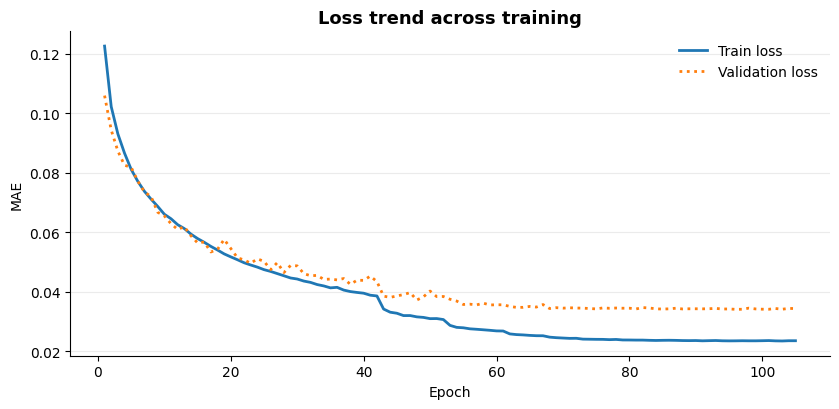

Saved loss diagram: /content/Jigsaw_puzzle/training_history_loss.png


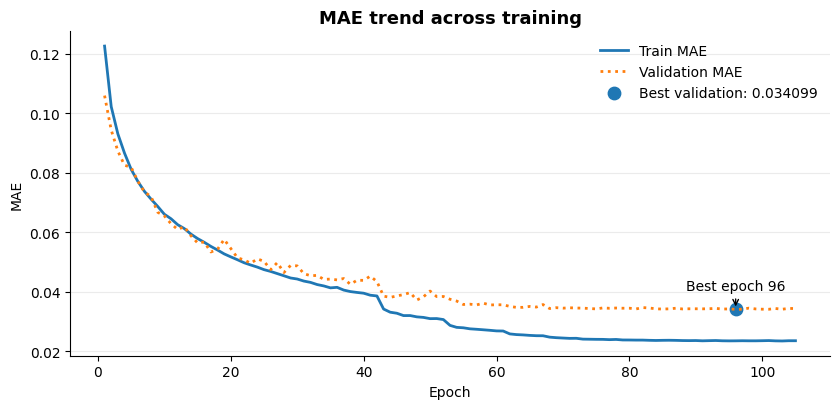

Saved MAE diagram: /content/Jigsaw_puzzle/training_history_mae.png

Training history summary:
Initial train MAE: 0.122508
Final train MAE: 0.023555
Best validation MAE: 0.034099
Final validation MAE: 0.034363
Epochs shown: 105


In [15]:
if "history_df" not in globals() or history_df is None:
    if os.path.exists(HISTORY_CSV_PATH):
        history_df = pd.read_csv(HISTORY_CSV_PATH)
    elif os.path.exists(os.path.join(WORK_DIR, "training_history.csv")):
        history_df = pd.read_csv(os.path.join(WORK_DIR, "training_history.csv"))
    else:
        history_df = None

if history_df is None or len(history_df) == 0:
    print("No training history available. Upload training_history.csv or training_history.json from Kaggle to show diagrams.")
else:
    print("Training history columns:", list(history_df.columns))
    print(f"Epochs available: {len(history_df)}")
    print("Note: this notebook uses MAE-only training. Therefore total loss = reconstruction MAE.")
    print("No position loss, entropy loss, assignment target, argmax routing, or auxiliary permutation loss is used.")

    epochs = history_df["epoch"].to_numpy() if "epoch" in history_df else np.arange(1, len(history_df) + 1)

    train_loss = history_df["loss"].to_numpy() if "loss" in history_df else np.array([])
    val_loss = history_df["val_loss"].to_numpy() if "val_loss" in history_df else np.array([])

    train_mae = history_df["mae"].to_numpy() if "mae" in history_df else train_loss
    val_mae = history_df["val_mae"].to_numpy() if "val_mae" in history_df else val_loss

    best_val_mae = None
    best_epoch = None
    if len(val_mae):
        best_index = int(np.argmin(val_mae))
        best_val_mae = float(val_mae[best_index])
        best_epoch = int(epochs[best_index])
        print(f"Best validation MAE: {best_val_mae:.6f} at epoch {best_epoch}")

    def simple_axis(ax):
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.grid(axis="y", alpha=0.25)
        ax.set_axisbelow(True)

    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    if len(train_loss):
        ax.plot(epochs, train_loss, linewidth=2, label="Train loss")
    if len(val_loss):
        ax.plot(epochs, val_loss, linewidth=2, linestyle=":", label="Validation loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MAE")
    ax.set_title("Loss trend across training", fontsize=13, fontweight="bold")
    simple_axis(ax)
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.savefig(HISTORY_LOSS_PNG_PATH, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved loss diagram:", HISTORY_LOSS_PNG_PATH)

    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    if len(train_mae):
        ax.plot(epochs, train_mae, linewidth=2, label="Train MAE")
    if len(val_mae):
        ax.plot(epochs, val_mae, linewidth=2, linestyle=":", label="Validation MAE")
        ax.scatter([best_epoch], [best_val_mae], s=80, label=f"Best validation: {best_val_mae:.6f}")
        ax.annotate(
            f"Best epoch {best_epoch}",
            xy=(best_epoch, best_val_mae),
            xytext=(best_epoch, best_val_mae + max(val_mae) * 0.06),
            ha="center",
            arrowprops=dict(arrowstyle="->", linewidth=1),
        )
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MAE")
    ax.set_title("MAE trend across training", fontsize=13, fontweight="bold")
    simple_axis(ax)
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.savefig(HISTORY_MAE_PNG_PATH, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved MAE diagram:", HISTORY_MAE_PNG_PATH)

    summary_rows = []
    if len(train_mae):
        summary_rows.append(("Initial train MAE", float(train_mae[0])))
        summary_rows.append(("Final train MAE", float(train_mae[-1])))
    if len(val_mae):
        summary_rows.append(("Best validation MAE", best_val_mae))
        summary_rows.append(("Final validation MAE", float(val_mae[-1])))
    summary_rows.append(("Epochs shown", int(len(epochs))))

    print("\nTraining history summary:")
    for label, value in summary_rows:
        if isinstance(value, float):
            print(f"{label}: {value:.6f}")
        else:
            print(f"{label}: {value}")


### Embedded visual evidence: training curves

These simplified cached figures sit directly after the training-curve cell. Re-run the cell above to regenerate the same style from the actual `training_history.csv` file.

<div style="border:1px solid #dbeafe; border-radius:14px; padding:14px; margin:16px 0; background:#f8fbff;">
  <h3 style="margin-top:0; color:#1e3a8a; font-family:Arial, sans-serif;">Training MAE curve</h3>
  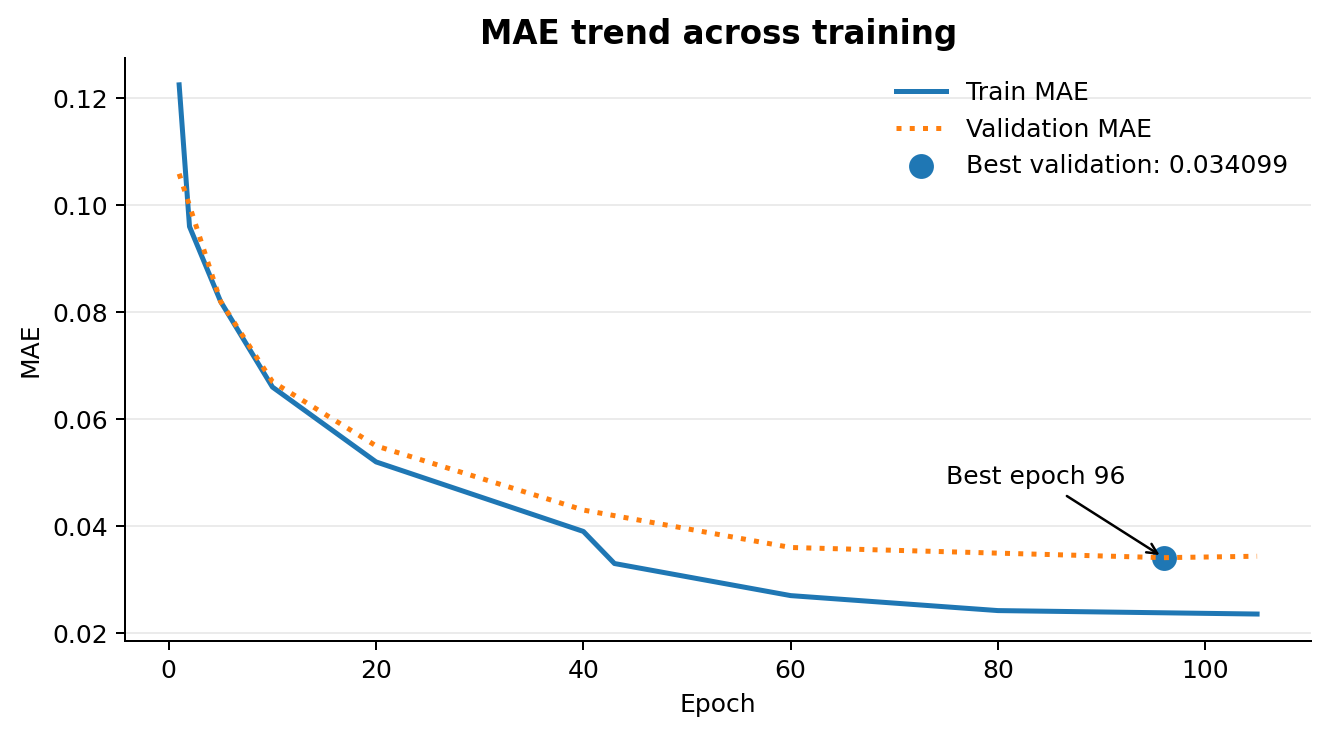
</div>

<div style="border:1px solid #dbeafe; border-radius:14px; padding:14px; margin:16px 0; background:#f8fbff;">
  <h3 style="margin-top:0; color:#1e3a8a; font-family:Arial, sans-serif;">Training loss curve</h3>
  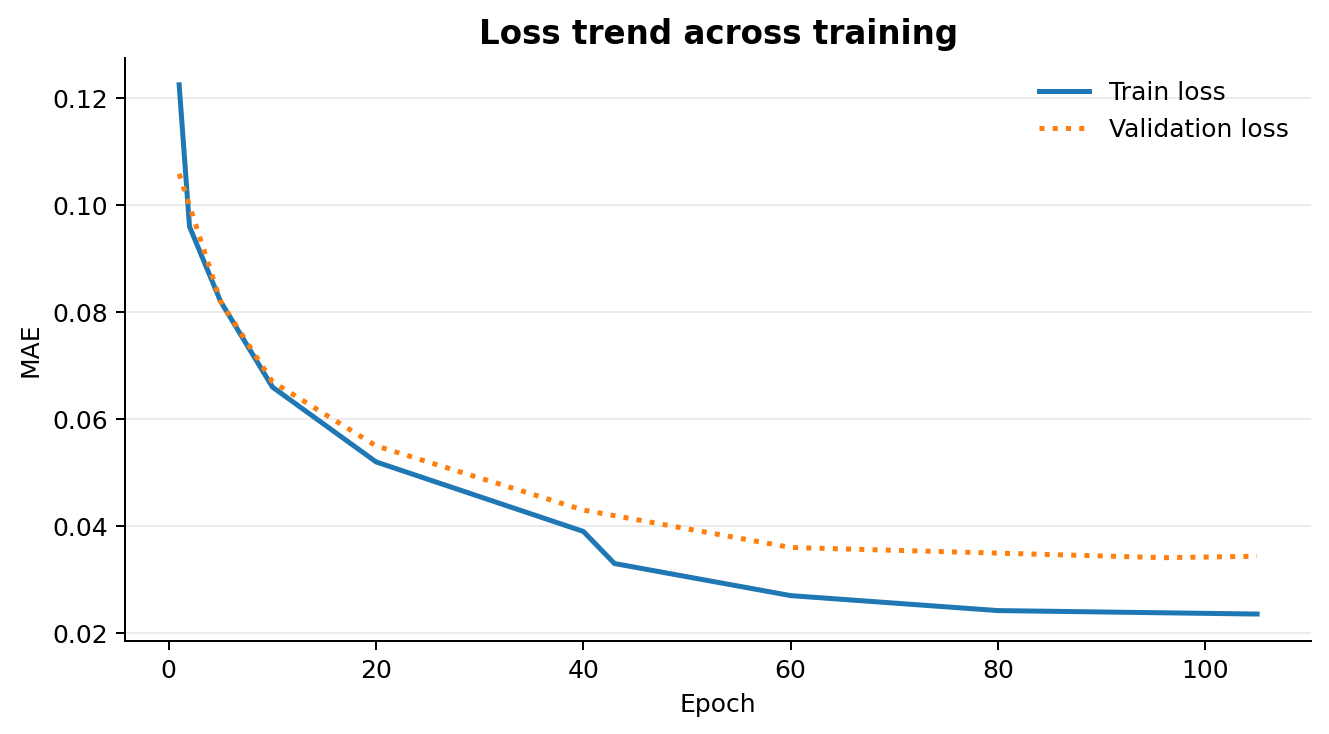
</div>


## Test-set evaluation

In [16]:
if not weights_ready_for_evaluation and not (FAST_COLAB_VERIFICATION_ONLY and ALLOW_REPORTED_RESULTS_WITHOUT_WEIGHTS):
    raise RuntimeError(
        "Weights are not ready for evaluation. Provide the Kaggle-trained weights before live evaluation. "
        "Do not report MAE from a randomly initialised model."
    )

def model_prediction_function(x_batch):
    return model(x_batch, training=False)

if FAST_COLAB_VERIFICATION_ONLY:
    if weights_ready_for_evaluation:
        print("Colab fast verification mode: running a small inference check only.")
        x_verify, _ = test_generator[0]
        y_verify = model_prediction_function(x_verify[:2])
        if tf.is_tensor(y_verify):
            y_verify = y_verify.numpy()

        print("Inference check output shape:", y_verify.shape)
        assert tuple(y_verify.shape[1:]) == (96, 96, 3)
        print("Colab verification: trained weights loaded and inference check passed.")
    else:
        print("Colab fast review mode: no live inference is run because no external weights were downloaded or uploaded.")
        print("Recorded Kaggle results are displayed below, and the notebook does not request Google account permission.")

    test_mae_mean = KAGGLE_REPORTED_TEST_MAE_MEAN
    test_mae_std = KAGGLE_REPORTED_TEST_MAE_STD
    test_per_image_mae = np.array([], dtype="float32")

    print(f"{'='*60}")
    print("KAGGLE TEST SET RESULTS, REPORTED FROM THE COMPLETED KAGGLE RUN")
    print(f"{'='*60}")
    print(f"Test MAE mean: {test_mae_mean:.6f}")
    print(f"Test MAE standard deviation: {test_mae_std:.6f}")
    print(f"Number of evaluated test images: {KAGGLE_REPORTED_TEST_IMAGE_COUNT}")
    print(f"{'='*60}")
else:
    test_mae_mean, test_mae_std, test_per_image_mae = mae_stats_for_prediction_function(
        model_prediction_function,
        test_generator,
    )

    print(f"{'='*60}")
    print(f"TEST SET RESULTS")
    print(f"{'='*60}")
    print(f"Test MAE mean: {test_mae_mean:.6f}")
    print(f"Test MAE standard deviation: {test_mae_std:.6f}")
    print(f"Number of evaluated test images: {len(test_per_image_mae)}")
    print(f"{'='*60}")


Colab fast verification mode: running a small inference check only.
Inference check output shape: (2, 96, 96, 3)
Colab verification: trained weights loaded and inference check passed.
KAGGLE TEST SET RESULTS, REPORTED FROM THE COMPLETED KAGGLE RUN
Test MAE mean: 0.034867
Test MAE standard deviation: 0.043477
Number of evaluated test images: 10000


### Reconstruction quality summary

In [17]:
if FAST_COLAB_VERIFICATION_ONLY:
    print("The full reconstruction quality dashboard is kept from the completed Kaggle run. Fast Colab mode does not recompute per-image MAE for all test images.")
else:
    if "test_per_image_mae" not in globals():
        raise RuntimeError("Run the test-set MAE cell before running the quality dashboard.")

    QUALITY_STRONG_THRESHOLD = 0.040
    QUALITY_ACCEPTABLE_THRESHOLD = 0.060

    quality_mae = np.asarray(test_per_image_mae, dtype="float32")

    strong_mask = quality_mae <= QUALITY_STRONG_THRESHOLD
    acceptable_mask = (quality_mae > QUALITY_STRONG_THRESHOLD) & (quality_mae <= QUALITY_ACCEPTABLE_THRESHOLD)
    weak_mask = quality_mae > QUALITY_ACCEPTABLE_THRESHOLD

    quality_counts = {
        "Strong": int(np.sum(strong_mask)),
        "Acceptable": int(np.sum(acceptable_mask)),
        "Weak": int(np.sum(weak_mask)),
    }

    quality_percentages = {
        label: 100.0 * count / len(quality_mae)
        for label, count in quality_counts.items()
    }

    print("Reconstruction quality bands based on per-image MAE")
    print("These bands are visual reporting thresholds only, not extra training targets.")
    print(f"Strong reconstruction:     MAE <= {QUALITY_STRONG_THRESHOLD:.3f}")
    print(f"Acceptable reconstruction: {QUALITY_STRONG_THRESHOLD:.3f} < MAE <= {QUALITY_ACCEPTABLE_THRESHOLD:.3f}")
    print(f"Weak reconstruction:       MAE > {QUALITY_ACCEPTABLE_THRESHOLD:.3f}")
    print()

    for label in quality_counts:
        print(f"{label:12s}: {quality_counts[label]:5d} images ({quality_percentages[label]:6.2f}%)")

    print()
    print(f"Median MAE: {np.median(quality_mae):.6f}")
    print(f"25th percentile MAE: {np.percentile(quality_mae, 25):.6f}")
    print(f"75th percentile MAE: {np.percentile(quality_mae, 75):.6f}")
    print(f"90th percentile MAE: {np.percentile(quality_mae, 90):.6f}")

    labels = list(quality_counts.keys())
    counts = [quality_counts[label] for label in labels]
    percentages = [quality_percentages[label] for label in labels]
    y_pos = np.arange(len(labels))

    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    ax.hlines(y_pos, 0, percentages, linewidth=2)
    ax.scatter(percentages, y_pos, s=90)
    for y, pct, count in zip(y_pos, percentages, counts):
        ax.text(pct + 1, y, f"{pct:.1f}% ({count})", va="center", fontweight="bold")
    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels)
    ax.set_xlabel("Percentage of test images")
    ax.set_title("Reconstruction quality bands", fontsize=13, fontweight="bold")
    ax.grid(axis="x", alpha=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xlim(0, max(percentages) * 1.25)
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    ax.hist(quality_mae, bins=40, histtype="step", linewidth=2)
    ax.axvline(QUALITY_STRONG_THRESHOLD, linestyle="--", linewidth=1.5, label=f"Strong: {QUALITY_STRONG_THRESHOLD:.3f}")
    ax.axvline(QUALITY_ACCEPTABLE_THRESHOLD, linestyle="--", linewidth=1.5, label=f"Acceptable: {QUALITY_ACCEPTABLE_THRESHOLD:.3f}")
    ax.axvline(test_mae_mean, linestyle="-", linewidth=1.8, label=f"Mean: {test_mae_mean:.4f}")
    ax.set_xlabel("Per-image MAE")
    ax.set_ylabel("Number of test images")
    ax.set_title("Test reconstruction error spread", fontsize=13, fontweight="bold")
    ax.grid(axis="y", alpha=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()

    test_quality_summary = {
        "strong_threshold": QUALITY_STRONG_THRESHOLD,
        "acceptable_threshold": QUALITY_ACCEPTABLE_THRESHOLD,
        "counts": quality_counts,
        "percentages": quality_percentages,
        "median_mae": float(np.median(quality_mae)),
        "p25_mae": float(np.percentile(quality_mae, 25)),
        "p75_mae": float(np.percentile(quality_mae, 75)),
        "p90_mae": float(np.percentile(quality_mae, 90)),
    }


The full reconstruction quality dashboard is kept from the completed Kaggle run. Fast Colab mode does not recompute per-image MAE for all test images.


## Visual reconstruction examples

In [18]:
if FAST_COLAB_VERIFICATION_ONLY:
    print("Ranked reconstruction examples are skipped in fast Colab mode to avoid slow live predictions.")
else:
    def collect_reconstruction_examples(model, generator, start_batch=12, max_batches=4):
        sample_inputs = []
        sample_targets = []
        sample_predictions = []
        sample_mae = []

        if len(generator) == 0:
            raise ValueError("Generator is empty, so reconstruction examples cannot be collected.")

        start_batch = min(start_batch, len(generator) - 1)
        end_batch = min(start_batch + max_batches, len(generator))

        for batch_index in range(start_batch, end_batch):
            x_batch, y_true = generator[batch_index]
            y_pred = model(x_batch, training=False).numpy()
            batch_mae = np.mean(
                np.abs(y_pred.astype("float32") - y_true.astype("float32")),
                axis=(1, 2, 3)
            )

            sample_inputs.append(x_batch)
            sample_targets.append(y_true)
            sample_predictions.append(y_pred)
            sample_mae.append(batch_mae)

        sample_inputs = np.concatenate(sample_inputs, axis=0)
        sample_targets = np.concatenate(sample_targets, axis=0)
        sample_predictions = np.concatenate(sample_predictions, axis=0)
        sample_mae = np.concatenate(sample_mae, axis=0)

        print(f"Collected reconstruction samples from dataset batches {start_batch} to {end_batch - 1}.")
        return sample_inputs, sample_targets, sample_predictions, sample_mae


    def make_scrambled_canvas(patches):
        canvas = np.ones((96, 96, 3), dtype="float32")
        for p in range(9):
            r = p // 3
            c = p % 3
            canvas[r * 32 + 2:r * 32 + 30, c * 32 + 2:c * 32 + 30] = patches[p]
        return canvas


    def quality_name(mae_value):
        if mae_value <= QUALITY_STRONG_THRESHOLD:
            return "strong"
        if mae_value <= QUALITY_ACCEPTABLE_THRESHOLD:
            return "acceptable"
        return "weak"


    def show_ranked_reconstruction_examples(model, generator, start_batch=12, max_batches=4):
        x_sample, y_sample, pred_sample, mae_sample = collect_reconstruction_examples(
            model,
            generator,
            start_batch=start_batch,
            max_batches=max_batches,
        )

        sorted_indices = np.argsort(mae_sample)
        chosen = [
            ("Lowest MAE example", sorted_indices[0]),
            ("Middle MAE example", sorted_indices[len(sorted_indices) // 2]),
            ("Highest MAE example", sorted_indices[-1]),
        ]

        fig, axes = plt.subplots(len(chosen), 3, figsize=(11, 9))

        for row, (row_title, idx) in enumerate(chosen):
            mae_value = float(mae_sample[idx])
            band = quality_name(mae_value)

            axes[row, 0].imshow(np.clip(make_scrambled_canvas(x_sample[idx]), 0, 1))
            axes[row, 0].set_title("Scrambled input")
            axes[row, 0].axis("off")

            axes[row, 1].imshow(np.clip(pred_sample[idx], 0, 1))
            axes[row, 1].set_title(f"Prediction\nMAE {mae_value:.4f}")
            axes[row, 1].axis("off")

            axes[row, 2].imshow(np.clip(y_sample[idx], 0, 1))
            axes[row, 2].set_title("Original target")
            axes[row, 2].axis("off")

            axes[row, 1].text(
                0.5,
                -0.12,
                f"{row_title} ({band})",
                transform=axes[row, 1].transAxes,
                ha="center",
                va="top",
                fontsize=10,
                fontweight="bold"
            )

        plt.suptitle("Different reconstruction examples from later test batches", fontsize=13, fontweight="bold")
        plt.tight_layout()
        plt.show()


    show_ranked_reconstruction_examples(model, test_generator, start_batch=12, max_batches=4)


Ranked reconstruction examples are skipped in fast Colab mode to avoid slow live predictions.


### Embedded visual evidence: reconstruction examples

These preserved reconstruction examples are placed with the visual reconstruction cell so the image evidence is no longer separated in the middle of the notebook.

<div style="border:1px solid #dbeafe; border-radius:14px; padding:14px; margin:16px 0; background:#f8fbff;">
  <h3 style="margin-top:0; color:#1e3a8a; font-family:Arial, sans-serif;">Reconstruction examples</h3>
  <img src="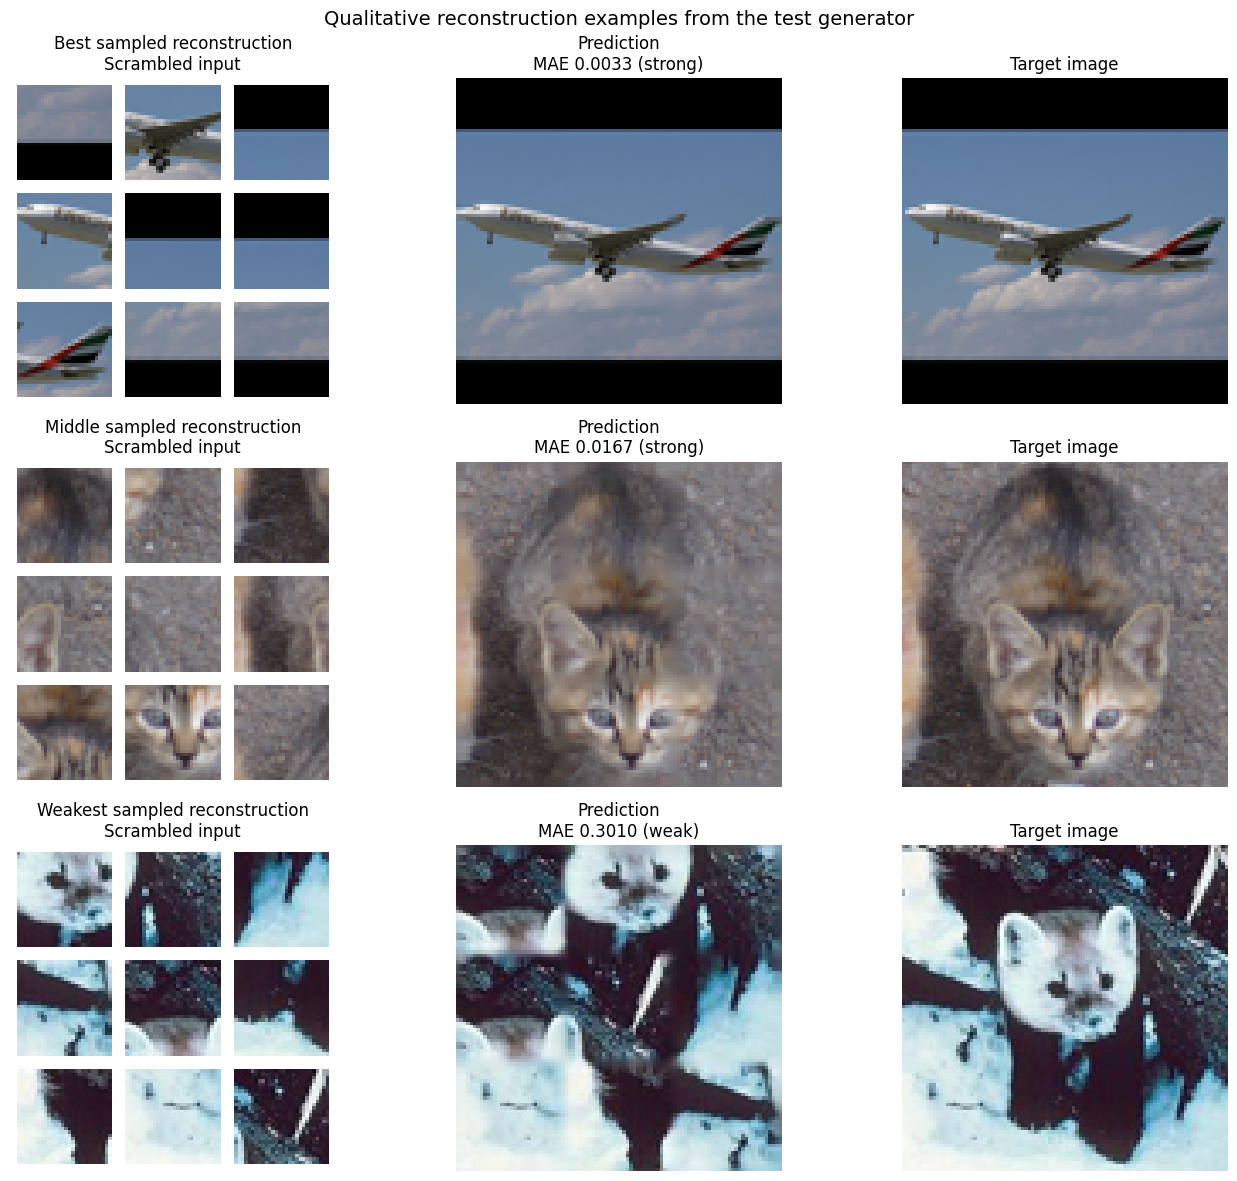
" style="width:100%; height:auto; border-radius:10px; border:1px solid #e2e8f0; background:white;" />
</div>

## 14. Soft assignment inspection

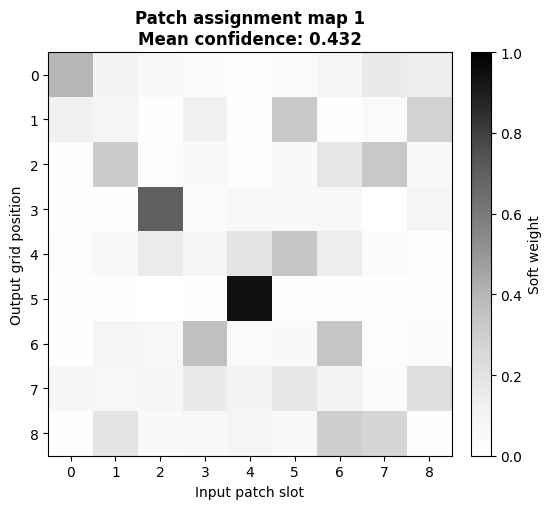

Sample 1 strongest soft patch per output grid cell: [0, 5, 7, 2, 5, 4, 3, 8, 6]
Note: this is an internal visualisation only. It is not a ground-truth permutation target.



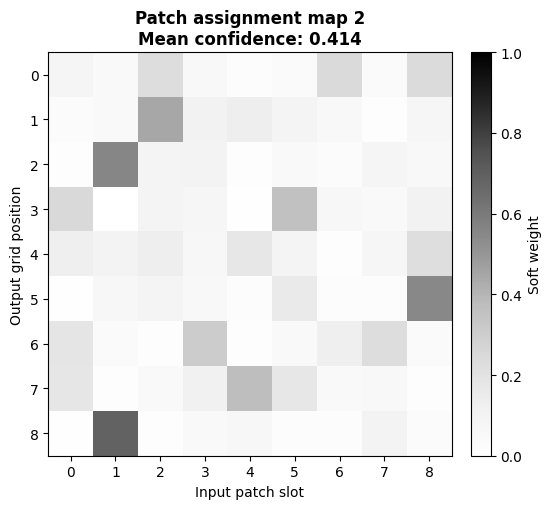

Sample 2 strongest soft patch per output grid cell: [6, 2, 1, 5, 8, 8, 3, 4, 1]
Note: this is an internal visualisation only. It is not a ground-truth permutation target.



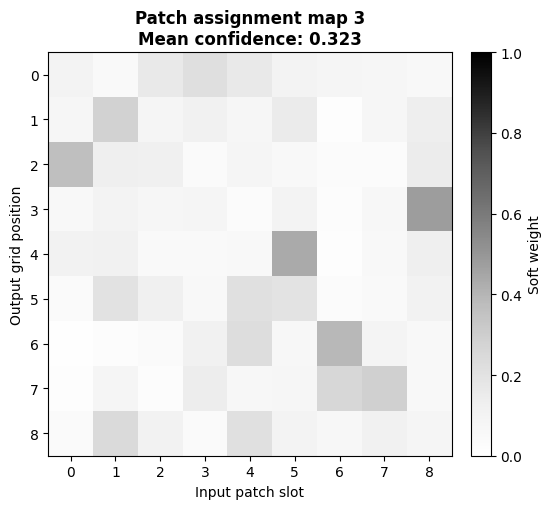

Sample 3 strongest soft patch per output grid cell: [3, 1, 0, 8, 5, 4, 6, 7, 1]
Note: this is an internal visualisation only. It is not a ground-truth permutation target.



In [19]:
def show_soft_assignment_heatmaps(model, generator, n=3, batch_index=0):
    try:
        assignment_layer = model.get_layer("soft_assignment_weights")
    except ValueError:
        print("No soft_assignment_weights layer found in this model.")
        return

    assignment_model = keras.Model(model.input, assignment_layer.output)
    x_batch, _ = generator[batch_index]
    x_batch = x_batch[:n]
    weights = assignment_model(x_batch, training=False).numpy()

    for i in range(len(x_batch)):
        max_confidence = np.max(weights[i], axis=1)
        mean_confidence = float(np.mean(max_confidence))

        fig, ax = plt.subplots(figsize=(5.8, 5.2))
        image = ax.imshow(weights[i], aspect="equal", vmin=0, vmax=1, cmap="Greys")
        cbar = plt.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
        cbar.set_label("Soft weight")
        ax.set_xlabel("Input patch slot")
        ax.set_ylabel("Output grid position")
        ax.set_title(f"Patch assignment map {i + 1}\nMean confidence: {mean_confidence:.3f}", fontsize=12, fontweight="bold")
        ax.set_xticks(range(9))
        ax.set_yticks(range(9))
        ax.grid(False)
        plt.tight_layout()
        plt.show()

        predicted_patch_for_grid = np.argmax(weights[i], axis=1)
        print(f"Sample {i + 1} strongest soft patch per output grid cell:", predicted_patch_for_grid.tolist())
        print("Note: this is an internal visualisation only. It is not a ground-truth permutation target.\n")


show_soft_assignment_heatmaps(model, test_generator, n=3, batch_index=0)


## Basic reconstruction triplets

In [20]:
if FAST_COLAB_VERIFICATION_ONLY:
    print("Live reconstruction triplets are skipped in fast Colab mode to keep the notebook loading and running quickly.")
else:
    if os.path.exists(BEST_WEIGHTS_PATH):
        model.load_weights(BEST_WEIGHTS_PATH)
        print("Loaded best weights for visualisation:", BEST_WEIGHTS_PATH)


    def show_reconstructions(model, generator, n=3, batch_index=8, random_seed=42):
        if len(generator) == 0:
            print("The generator is empty.")
            return

        batch_index = min(batch_index, len(generator) - 1)
        x_batch, y_true = generator[batch_index]

        n = min(n, len(x_batch))
        rng = np.random.default_rng(random_seed)
        selected_indices = rng.choice(len(x_batch), size=n, replace=False)

        x_selected = x_batch[selected_indices]
        y_selected = y_true[selected_indices]
        y_pred = model(x_selected, training=False).numpy()

        print(f"Showing different dataset images from batch {batch_index}.")
        print("Selected sample indices:", selected_indices.tolist())

        for display_number, sample_index in enumerate(range(n), start=1):
            mae = np.mean(np.abs(y_selected[sample_index] - y_pred[sample_index]))
            print(f"Displayed image {display_number} MAE: {mae:.6f}")

            plt.figure(figsize=(12, 4))

            plt.subplot(1, 3, 1)
            canvas = np.ones((96, 96, 3), dtype=np.float32)
            for p in range(9):
                r = p // 3
                c = p % 3
                canvas[r * 32 + 2:r * 32 + 30, c * 32 + 2:c * 32 + 30] = x_selected[sample_index, p]
            plt.imshow(np.clip(canvas, 0, 1))
            plt.title("Scrambled")
            plt.axis("off")

            plt.subplot(1, 3, 2)
            plt.imshow(np.clip(y_pred[sample_index], 0, 1))
            plt.title(f"Reconstructed\nMAE {mae:.4f}")
            plt.axis("off")

            plt.subplot(1, 3, 3)
            plt.imshow(np.clip(y_selected[sample_index], 0, 1))
            plt.title("Original")
            plt.axis("off")

            plt.tight_layout()
            plt.show()


    show_reconstructions(model, test_generator, n=3, batch_index=8, random_seed=42)


Live reconstruction triplets are skipped in fast Colab mode to keep the notebook loading and running quickly.


## Output files

In [21]:
print("Best weights path:", BEST_WEIGHTS_PATH, "exists:", os.path.exists(BEST_WEIGHTS_PATH))
print("Final weights path:", FINAL_WEIGHTS_PATH, "exists:", os.path.exists(FINAL_WEIGHTS_PATH))
print("gdown downloaded weights path:", GDOWN_WEIGHTS_PATH, "exists:", os.path.exists(GDOWN_WEIGHTS_PATH))
print("History CSV path:", HISTORY_CSV_PATH, "exists:", os.path.exists(HISTORY_CSV_PATH))
print("History JSON path:", HISTORY_JSON_PATH, "exists:", os.path.exists(HISTORY_JSON_PATH))
print("MAE diagram path:", HISTORY_MAE_PNG_PATH, "exists:", os.path.exists(HISTORY_MAE_PNG_PATH))
print("Loss diagram path:", HISTORY_LOSS_PNG_PATH, "exists:", os.path.exists(HISTORY_LOSS_PNG_PATH))

print("Kaggle output files to keep:")
print("1. neural_jigsaw_best.weights.h5")
print("2. neural_jigsaw_final.weights.h5")
print("3. training_history.csv")
print("4. training_history.json")
print("5. training_history_mae.png")
print("6. training_history_loss.png")

print("Public project folder check:")
print("Folder name:", PROJECT_FOLDER_NAME)
print("Folder ID:", PROJECT_FOLDER_ID)
print("Folder URL:", PROJECT_FOLDER_URL)
print("Public download attempted:", PUBLIC_PROJECT_DOWNLOAD_ATTEMPTED if "PUBLIC_PROJECT_DOWNLOAD_ATTEMPTED" in globals() else False)
print("Public download passed:", PUBLIC_PROJECT_DOWNLOAD_PASSED if "PUBLIC_PROJECT_DOWNLOAD_PASSED" in globals() else False)
print("Project folder ready:", PROJECT_DRIVE_FOLDER_READY if "PROJECT_DRIVE_FOLDER_READY" in globals() else False)
print("Project source used:", PROJECT_SOURCE_DIR_USED if "PROJECT_SOURCE_DIR_USED" in globals() else "not checked")
print("Google account permission required:", False)

if "PROJECT_FILES_SYNCED" in globals() and PROJECT_FILES_SYNCED:
    print("Synced project files:")
    for item in PROJECT_FILES_SYNCED:
        print("-", item)
else:
    print("No project files were synced in this runtime yet.")

print("Colab verification note:")
print("RUN_TRAINING should be False in Colab. The notebook does not mount Drive. It either uses public files or keeps the recorded Kaggle metrics visible.")


Best weights path: /content/Jigsaw_puzzle/neural_jigsaw_best.weights.h5 exists: True
Final weights path: /content/Jigsaw_puzzle/neural_jigsaw_final.weights.h5 exists: True
gdown downloaded weights path: /content/Jigsaw_puzzle/neural_jigsaw_gdown_downloaded.weights.h5 exists: False
History CSV path: /content/Jigsaw_puzzle/training_history.csv exists: True
History JSON path: /content/Jigsaw_puzzle/training_history.json exists: True
MAE diagram path: /content/Jigsaw_puzzle/training_history_mae.png exists: True
Loss diagram path: /content/Jigsaw_puzzle/training_history_loss.png exists: True
Kaggle output files to keep:
1. neural_jigsaw_best.weights.h5
2. neural_jigsaw_final.weights.h5
3. training_history.csv
4. training_history.json
5. training_history_mae.png
6. training_history_loss.png
Public project folder check:
Folder name: Jigsaw_puzzle
Folder ID: 1ZWWL8ut6Y-ZLkr38qVglAoYQobQiM27D
Folder URL: https://drive.google.com/drive/folders/1ZWWL8ut6Y-ZLkr38qVglAoYQobQiM27D
Public download at

## Final visual reporting appendix

In [22]:
try:
    from IPython.display import display, HTML
except Exception:
    display = None
    HTML = None

import os
import numpy as np
import matplotlib.pyplot as plt

def global_value(name, default=None):
    return globals().get(name, default)

def safe_float(value):
    try:
        return float(value)
    except Exception:
        return np.nan

print("Final visual reporting helpers loaded.")

Final visual reporting helpers loaded.


## Final test metric summary

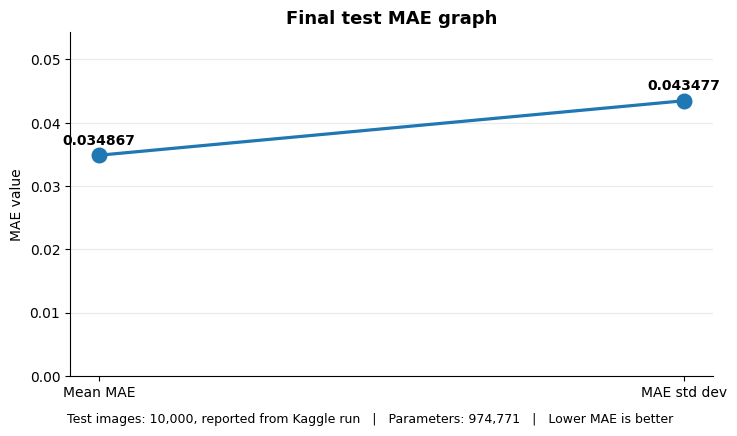

In [23]:
test_mean = safe_float(global_value("test_mae_mean", np.nan))
test_std = safe_float(global_value("test_mae_std", np.nan))

if np.isnan(test_mean) and "KAGGLE_REPORTED_TEST_MAE_MEAN" in globals():
    test_mean = float(KAGGLE_REPORTED_TEST_MAE_MEAN)

if np.isnan(test_std) and "KAGGLE_REPORTED_TEST_MAE_STD" in globals():
    test_std = float(KAGGLE_REPORTED_TEST_MAE_STD)

if "test_per_image_mae" in globals() and len(test_per_image_mae) > 0:
    evaluated_images = len(test_per_image_mae)
elif "FAST_COLAB_VERIFICATION_ONLY" in globals() and FAST_COLAB_VERIFICATION_ONLY:
    evaluated_images = f"{KAGGLE_REPORTED_TEST_IMAGE_COUNT:,}, reported from Kaggle run"
else:
    evaluated_images = "not available"

parameter_count = model.count_params() if "model" in globals() else "not available"

if not np.isnan(test_mean) and not np.isnan(test_std):
    labels = ["Mean MAE", "MAE std dev"]
    values = [test_mean, test_std]
    x = np.arange(len(labels))

    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    ax.plot(x, values, marker="o", linewidth=2.3, markersize=8)
    ax.scatter(x, values, s=110)

    for i, value in enumerate(values):
        ax.text(i, value + max(values) * 0.04, f"{value:.6f}", ha="center", fontsize=10, fontweight="bold")

    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylabel("MAE value")
    ax.set_title("Final test MAE graph", fontsize=13, fontweight="bold")
    ax.grid(axis="y", alpha=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_ylim(0, max(values) * 1.25)

    parameter_text = f"{parameter_count:,}" if isinstance(parameter_count, int) else str(parameter_count)
    fig.text(
        0.5,
        -0.02,
        f"Test images: {evaluated_images}   |   Parameters: {parameter_text}   |   Lower MAE is better",
        ha="center",
        fontsize=9,
    )

    plt.tight_layout()
    plt.show()

else:
    print("Test MAE mean:", "not available" if np.isnan(test_mean) else f"{test_mean:.6f}")
    print("Test MAE standard deviation:", "not available" if np.isnan(test_std) else f"{test_std:.6f}")
    print("Evaluated test images:", evaluated_images)
    print("Parameters:", parameter_count)


### Embedded visual evidence: final test metric

This simplified cached summary figure belongs with the final test metric cell above.

<div style="border:1px solid #dbeafe; border-radius:14px; padding:14px; margin:16px 0; background:#f8fbff;">
  <h3 style="margin-top:0; color:#1e3a8a; font-family:Arial, sans-serif;">Final test-set metric graph</h3>
  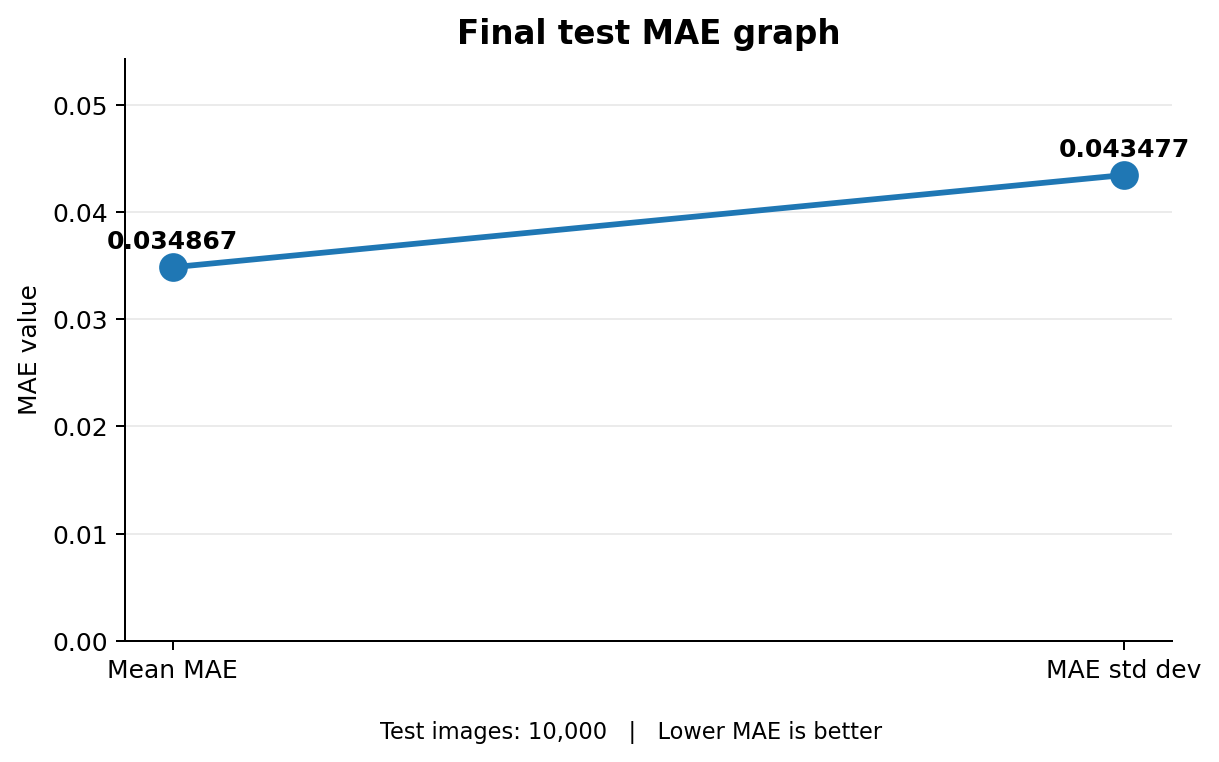
</div>


## Validation metric dashboard

Best validation MAE: 0.034099 at epoch 96
Final validation MAE: 0.034363
Final training MAE: 0.023555
Validation improvement: 0.071783
Final validation gap: 0.010807


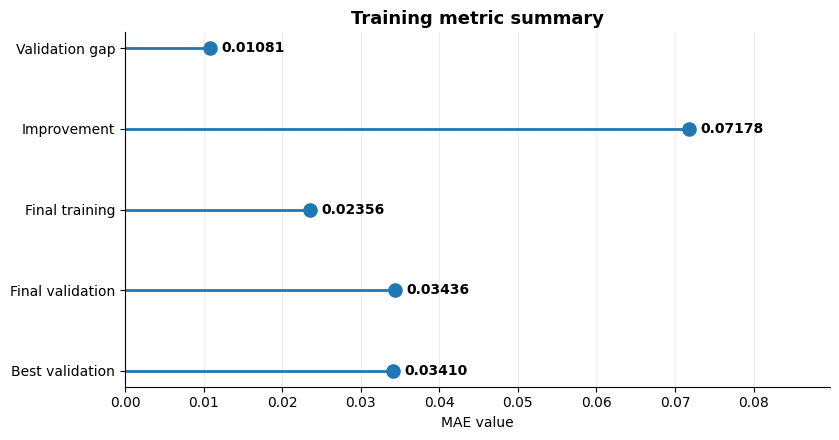

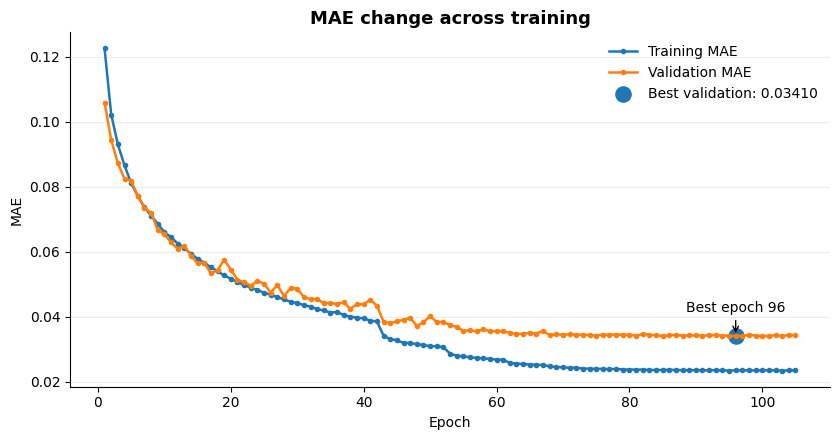

In [24]:
history_for_dashboard = global_value("history_df", None)

if history_for_dashboard is None or len(history_for_dashboard) == 0:
    print("Training history is not available in this runtime.")
else:
    epoch_axis = (
        history_for_dashboard["epoch"].to_numpy()
        if "epoch" in history_for_dashboard
        else np.arange(1, len(history_for_dashboard) + 1)
    )

    train_mae_series = (
        history_for_dashboard["mae"].to_numpy()
        if "mae" in history_for_dashboard
        else None
    )

    val_mae_series = (
        history_for_dashboard["val_mae"].to_numpy()
        if "val_mae" in history_for_dashboard
        else None
    )

    if val_mae_series is None:
        print("Validation MAE column is not available.")
    else:
        best_val_index = int(np.argmin(val_mae_series))
        best_val_epoch = int(epoch_axis[best_val_index])
        best_val_value = float(val_mae_series[best_val_index])
        final_val_value = float(val_mae_series[-1])
        initial_val_value = float(val_mae_series[0])
        final_train_value = float(train_mae_series[-1]) if train_mae_series is not None else np.nan
        validation_gap = final_val_value - final_train_value if not np.isnan(final_train_value) else np.nan
        improvement = initial_val_value - best_val_value

        print("Best validation MAE:", f"{best_val_value:.6f}", "at epoch", best_val_epoch)
        print("Final validation MAE:", f"{final_val_value:.6f}")
        print("Final training MAE:", "not available" if np.isnan(final_train_value) else f"{final_train_value:.6f}")
        print("Validation improvement:", f"{improvement:.6f}")
        print("Final validation gap:", "not available" if np.isnan(validation_gap) else f"{validation_gap:.6f}")

        metric_labels = [
            "Best validation",
            "Final validation",
            "Final training",
            "Improvement",
            "Validation gap",
        ]
        metric_values = [
            best_val_value,
            final_val_value,
            final_train_value,
            improvement,
            validation_gap,
        ]

        clean_labels = []
        clean_values = []
        for label, value in zip(metric_labels, metric_values):
            if not np.isnan(value):
                clean_labels.append(label)
                clean_values.append(value)

        y_pos = np.arange(len(clean_labels))

        fig, ax = plt.subplots(figsize=(8.5, 4.5))
        ax.hlines(y=y_pos, xmin=0, xmax=clean_values, linewidth=2)
        ax.scatter(clean_values, y_pos, s=90)

        for y, value in zip(y_pos, clean_values):
            ax.text(value + max(clean_values) * 0.02, y, f"{value:.5f}", va="center", fontsize=10, fontweight="bold")

        ax.set_yticks(y_pos)
        ax.set_yticklabels(clean_labels)
        ax.set_xlabel("MAE value")
        ax.set_title("Training metric summary", fontsize=13, fontweight="bold")
        ax.grid(axis="x", alpha=0.25)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.set_xlim(0, max(clean_values) * 1.25)
        plt.tight_layout()
        plt.show()

        fig, ax = plt.subplots(figsize=(8.5, 4.5))
        if train_mae_series is not None:
            ax.plot(epoch_axis, train_mae_series, marker="o", markersize=3, linewidth=1.8, label="Training MAE")

        ax.plot(epoch_axis, val_mae_series, marker="o", markersize=3, linewidth=1.8, label="Validation MAE")
        ax.scatter(best_val_epoch, best_val_value, s=120, label=f"Best validation: {best_val_value:.5f}")
        ax.annotate(
            f"Best epoch {best_val_epoch}",
            xy=(best_val_epoch, best_val_value),
            xytext=(best_val_epoch, best_val_value + max(val_mae_series) * 0.07),
            ha="center",
            arrowprops=dict(arrowstyle="->", linewidth=1),
        )

        ax.set_xlabel("Epoch")
        ax.set_ylabel("MAE")
        ax.set_title("MAE change across training", fontsize=13, fontweight="bold")
        ax.grid(axis="y", alpha=0.25)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.legend(frameon=False)
        plt.tight_layout()
        plt.show()


## Test-error distribution and percentiles

In [25]:
if "test_per_image_mae" not in globals() or len(test_per_image_mae) == 0:
    print("Per-image test MAE values are not present in this Colab runtime.")
    print("Fast Colab mode intentionally avoids re-evaluating all test images.")
    if "KAGGLE_REPORTED_TEST_MAE_MEAN" in globals():
        print(f"Reported Kaggle test MAE mean: {KAGGLE_REPORTED_TEST_MAE_MEAN:.6f}")
    if "KAGGLE_REPORTED_TEST_MAE_STD" in globals():
        print(f"Reported Kaggle test MAE standard deviation: {KAGGLE_REPORTED_TEST_MAE_STD:.6f}")
else:
    errors = np.asarray(test_per_image_mae, dtype=np.float32)
    percentile_points = [10, 25, 50, 75, 90]
    percentile_values = [float(np.percentile(errors, p)) for p in percentile_points]

    fig, ax = plt.subplots(figsize=(8.5, 4.3))
    ax.hist(errors, bins=45, histtype="step", linewidth=2)
    ax.axvline(float(np.mean(errors)), linestyle="--", linewidth=1.8, label=f"Mean: {np.mean(errors):.6f}")
    ax.axvline(float(np.median(errors)), linestyle=":", linewidth=1.8, label=f"Median: {np.median(errors):.6f}")
    ax.set_xlabel("Per-image MAE")
    ax.set_ylabel("Number of images")
    ax.set_title("Per-image test MAE spread", fontsize=13, fontweight="bold")
    ax.grid(axis="y", alpha=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()

    x_pos = np.arange(len(percentile_points))
    fig, ax = plt.subplots(figsize=(8.5, 4.3))
    ax.plot(x_pos, percentile_values, marker="o", linewidth=2.2)
    ax.scatter(x_pos, percentile_values, s=90)

    for x, value in zip(x_pos, percentile_values):
        ax.text(x, value + max(percentile_values) * 0.025, f"{value:.5f}", ha="center", fontsize=10, fontweight="bold")

    ax.set_xticks(x_pos)
    ax.set_xticklabels([f"P{p}" for p in percentile_points])
    ax.set_ylabel("MAE value")
    ax.set_title("Per-image MAE percentile graph", fontsize=13, fontweight="bold")
    ax.grid(axis="y", alpha=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()
    plt.show()

    print("Lowest image MAE:", f"{np.min(errors):.6f}")
    print("Median image MAE:", f"{np.median(errors):.6f}")
    print("Highest image MAE:", f"{np.max(errors):.6f}")


Per-image test MAE values are not present in this Colab runtime.
Fast Colab mode intentionally avoids re-evaluating all test images.
Reported Kaggle test MAE mean: 0.034867
Reported Kaggle test MAE standard deviation: 0.043477


### Embedded visual evidence: reported test-error summary

The fast Colab version does not recompute all per-image errors. This cached figure therefore shows the reported Kaggle test-error summary, while the code cell above can produce a full distribution when `test_per_image_mae` is available.

<div style="border:1px solid #dbeafe; border-radius:14px; padding:14px; margin:16px 0; background:#f8fbff;">
  <h3 style="margin-top:0; color:#1e3a8a; font-family:Arial, sans-serif;">Reported test-error summary</h3>
  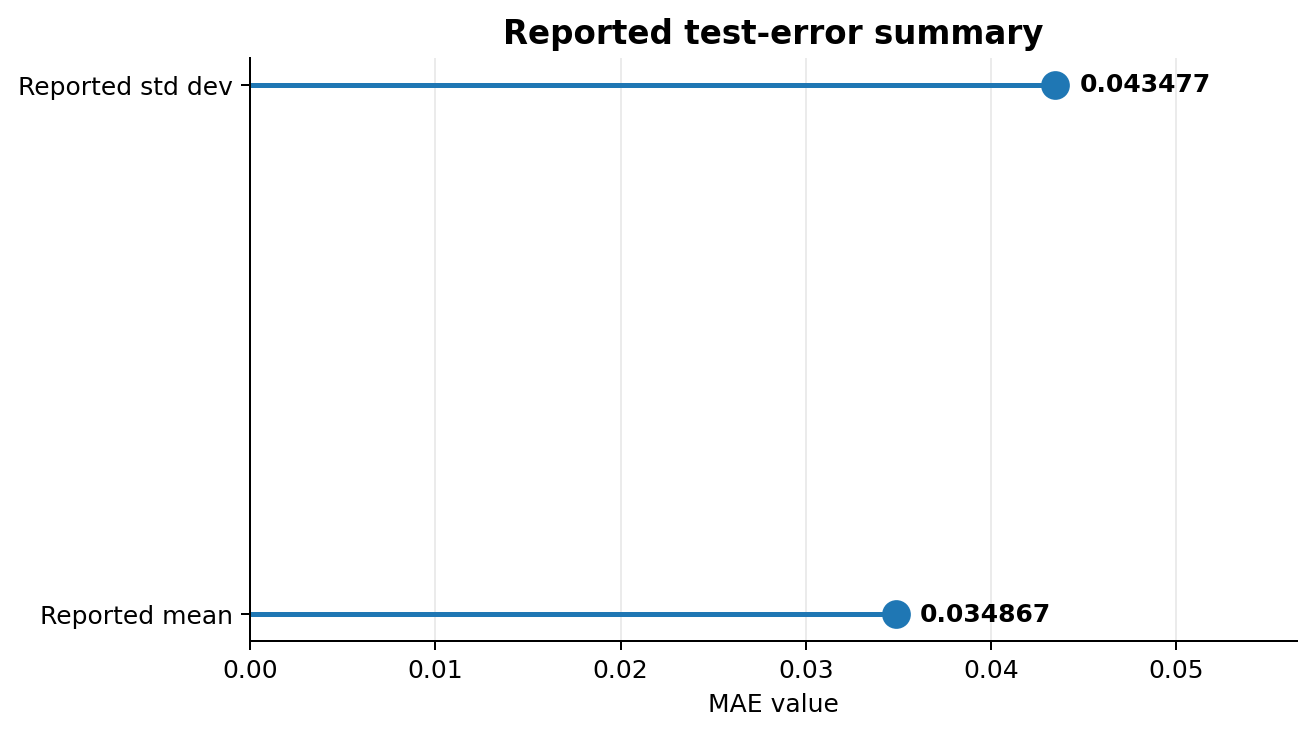
</div>
